# Chest X-Ray Pneumonia: V5 and Development Record

**Latest experiment: V5 EfficientNetV2B0, 320 x 320.** In a new runtime, run preparation cells 39–41, then V5 cells 47–54. This trains only V5. Cells 1–37 and 42–46 preserve earlier V2/V3/V4 development and results. Prefer the separately delivered clean V5 notebook for a fresh run. The final plain-text comparison is in cell 54.

**V5 data and selection.** Fit / validation / historical benchmark: 3,781 / 956 / 624 images. Source-stratified grouped validation contains both IM and NORMAL2 filename-prefix NORMAL groups and PNEUMONIA groups. Filename proxies and exact-byte duplicates are separated; source components sharing proxies or bytes with the historical benchmark are excluded. Clinical patient identity, scanner/site identity and near-duplicates remain unverified. Checkpoint and threshold decisions use validation precision and recall floors of 0.95; the selected model and threshold are saved before V5 historical inference.

**Development record.** V1 used test-selected threshold 0.85. V2 corrected threshold selection but increased false alarms. V3 improved V2 without surpassing V1 in every metric. V4 normalization and source holdout also failed that target; those results are retained. V5 is a new adaptive experiment designed after those historical results. No V5 model or threshold adjustment follows its score.

**Evidence limits.** The official test was inspected and informed development. Report a descriptive historical-benchmark comparison, not independent unseen-test evidence or statistical/clinical superiority. Its 624 files contain 618 distinct byte hashes; duplicate-aware supplemental metrics are provided separately from the same-denominator historical comparison. Validation is used for selection, scores are uncalibrated, and Grad-CAM is qualitative. This is a research/educational prototype.

**Preserve files.** A prior temporary Colab runtime was discarded, so V4 was retrained and saved outside Colab before V5 began. Final deliverables include the selected V5 model, locked decision policy, split and duplicate audit, predictions, comparison and figures. Keep the ZIP outside the temporary runtime.


In [ ]:
import os
import json
import platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
RUN_DIR = Path('/content/pneumonia_runs') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
MODEL_PATH = RUN_DIR / 'pneumonia_mobilenetv2_gradcam.keras'
print('TensorFlow version:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))
print('Run directory:', RUN_DIR)
print('Existing model in memory:', 'model' in globals())
print('Existing model files:', [str(p) for p in Path('/content').glob('*.keras')])

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Run directory: /content/pneumonia_runs/20261022T065237_860984Z
Existing model in memory: True
Existing model files: []


In [ ]:
# Public dataset access; credentials are not stored in this notebook.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('kagglehub') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
import kagglehub
print('KaggleHub is ready.')

KaggleHub is ready.


In [ ]:
from pathlib import Path

DATASET_HANDLE = 'paultimothymooney/chest-xray-pneumonia'
# Reuse the download cache. Existing data and credentials are never deleted.
dataset_root = Path(kagglehub.dataset_download(DATASET_HANDLE))
candidate_dirs = sorted(
    [p for p in [dataset_root, *dataset_root.rglob('chest_xray')]
     if (p / 'train' / 'NORMAL').is_dir()
     and (p / 'train' / 'PNEUMONIA').is_dir()
     and (p / 'test' / 'NORMAL').is_dir()
     and (p / 'test' / 'PNEUMONIA').is_dir()],
    key=lambda p: (len(p.parts), str(p))
)
if not candidate_dirs:
    raise FileNotFoundError('No valid train/test dataset root was found.')
base_dir = candidate_dirs[0]
train_dir, val_dir, test_dir = [base_dir / s for s in ('train', 'val', 'test')]
print('Dataset cache:', dataset_root)
print('Selected dataset root:', base_dir)
print('The supplied val directory is not used; validation is split from train.')

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset cache: /kaggle/input/chest-xray-pneumonia
Selected dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray
The supplied val directory is not used; validation is split from train.


In [ ]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
for split in ['train', 'val', 'test']:
    print(f'\n{split.upper()} (source directory)')
    for cls in ['NORMAL', 'PNEUMONIA']:
        folder = base_dir / split / cls
        count = sum(p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES for p in folder.glob('*'))
        print(f'{cls}: {count}')


TRAIN (source directory)
NORMAL: 1341
PNEUMONIA: 3875

VAL (source directory)
NORMAL: 8
PNEUMONIA: 8

TEST (source directory)
NORMAL: 234
PNEUMONIA: 390


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CLASS_NAMES = ['NORMAL', 'PNEUMONIA']
VALIDATION_FRACTION = 0.15

# One seeded call creates complementary subsets; do not change shuffle for only one subset.
train_ds_raw, val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=VALIDATION_FRACTION, subset='both',
    seed=SEED, shuffle=True, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='binary', class_names=CLASS_NAMES, interpolation='bilinear'
)
test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir, shuffle=False, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='binary', class_names=CLASS_NAMES, interpolation='bilinear'
)
class_names = list(train_ds_raw.class_names)
train_paths = list(train_ds_raw.file_paths)
val_paths = list(val_ds_raw.file_paths)
test_file_paths = np.array(test_ds_raw.file_paths)
assert not (set(train_paths) & set(val_paths)), 'Train/validation path overlap.'
assert not ((set(train_paths) | set(val_paths)) & set(test_file_paths)), 'Test path overlap.'

def ordered_dataset(paths):
    labels = np.array([class_names.index(Path(p).parent.name) for p in paths], dtype=np.float32)
    def read_image(path, label):
        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMG_SIZE, method='bilinear')
        return image, tf.reshape(label, (1,))
    return tf.data.Dataset.from_tensor_slices((list(paths), labels)).map(
        read_image, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True
    ).batch(BATCH_SIZE)

# This uses the exact selected validation files, with a stable order for prediction export.
val_ds_ordered = ordered_dataset(val_paths)
split_manifest = {'seed': SEED, 'validation_fraction': VALIDATION_FRACTION,
    'class_names': class_names,
    'files': {split: [str(Path(p).relative_to(base_dir)) for p in paths]
              for split, paths in [('train', train_paths), ('validation', val_paths), ('test', test_file_paths)]}}
(RUN_DIR / 'split_manifest.json').write_text(json.dumps(split_manifest, indent=2))
print('Actual split sizes:', len(train_paths), len(val_paths), len(test_file_paths))
print('Class mapping:', dict(enumerate(class_names)))

Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Using 782 files for validation.
Found 624 files belonging to 2 classes.
Actual split sizes: 4434 782 624
Class mapping: {0: 'NORMAL', 1: 'PNEUMONIA'}


In [ ]:
from collections import Counter

counts = Counter(class_names.index(Path(p).parent.name) for p in train_paths)
assert set(counts) == {0, 1}, 'Both classes must be present in training.'
total = sum(counts.values())
class_weight = {class_id: total / (2 * count) for class_id, count in counts.items()}
print('Training class counts:', counts)
print('Training class weights:', class_weight)

Training class counts: Counter({1: 3283, 0: 1151})
Training class weights: {1: 0.675296984465428, 0: 1.9261511728931364}


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
# Shuffle individual training images, rather than cached batches.
train_ds = train_ds_raw.unbatch().cache().shuffle(
    min(1000, len(train_paths)), seed=SEED, reshuffle_each_iteration=True
).batch(BATCH_SIZE).apply(tf.data.experimental.assert_cardinality(
    (len(train_paths) + BATCH_SIZE - 1) // BATCH_SIZE
)).prefetch(AUTOTUNE)
val_ds = val_ds_ordered.cache().prefetch(AUTOTUNE)
test_ds = test_ds_raw.prefetch(AUTOTUNE)

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.10),
], name="data_augmentation")

base_model = MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=IMG_SIZE + (3,), name="input_image")

x = data_augmentation(inputs)
x = preprocess_input(x)

x = base_model(x, training=False)


x = layers.Activation("linear", name="last_conv_features")(x)

x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.30, name="dropout")(x)

outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)


print("Base model trainable:", base_model.trainable)

model.summary()

Base model trainable: False


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv_features (Activation) │ (None, 7, 7, 1280)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 18s 85ms/step - accuracy: 0.8351 - auc: 0.9226 - loss: 0.3637 - precision: 0.9391 - recall: 0.8313 - val_accuracy: 0.9335 - val_auc: 0.9689 - val_loss: 0.1942 - val_precision: 0.9576 - val_recall: 0.9544 - learning_rate: 0.0010
Epoch 2/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 10s 70ms/step - accuracy: 0.9206 - auc: 0.9787 - loss: 0.1987 - precision: 0.9753 - recall: 0.9159 - val_accuracy: 0.9373 - val_auc: 0.9760 - val_loss: 0.1632 - val_precision: 0.9657 - val_recall: 0.9510 - learning_rate: 0.0010
Epoch 3/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.9317 - auc: 0.9852 - loss: 0.1629 - precision: 0.9816 - recall: 0.9251 - val_accuracy: 0.9361 - val_auc: 0.9780 - val_loss: 0.1546 - val_precision: 0.9738 - val_recall: 0.9409 - learning_rate: 0.0010
Epoch 4/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - accuracy: 0.9409 - auc: 0.9874 - loss: 0.1484 - precision: 0.9827 - recall: 0.9366 - val_accuracy: 0.9501 - val_auc: 0.9818 - val_loss: 0.1384 - v

In [ ]:

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)


print("Base model trainable:", base_model.trainable)

trainable_count = sum([layer.trainable for layer in base_model.layers])
print("Number of trainable layers in the base model:", trainable_count)

Base model trainable: True
Number of trainable layers in the base model: 30


In [ ]:
history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weight,
    callbacks=callbacks
)

# Save fitted weights before any test inference.
model.save(MODEL_PATH)
print('Fitted model saved:', MODEL_PATH)

Epoch 1/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 23s 97ms/step - accuracy: 0.9186 - auc: 0.9713 - loss: 0.2326 - precision: 0.9537 - recall: 0.9354 - val_accuracy: 0.9629 - val_auc: 0.9861 - val_loss: 0.1166 - val_precision: 0.9747 - val_recall: 0.9764 - learning_rate: 1.0000e-05
Epoch 2/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.9407 - auc: 0.9867 - loss: 0.1433 - precision: 0.9849 - recall: 0.9342 - val_accuracy: 0.9616 - val_auc: 0.9869 - val_loss: 0.1126 - val_precision: 0.9845 - val_recall: 0.9645 - learning_rate: 1.0000e-05
Epoch 3/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 12s 87ms/step - accuracy: 0.9461 - auc: 0.9877 - loss: 0.1364 - precision: 0.9838 - recall: 0.9427 - val_accuracy: 0.9668 - val_auc: 0.9881 - val_loss: 0.1045 - val_precision: 0.9879 - val_recall: 0.9679 - learning_rate: 1.0000e-05
Epoch 4/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.9506 - auc: 0.9901 - loss: 0.1206 - precision: 0.9845 - recall: 0.9482 - val_accuracy: 0.9616 - val_auc: 0.9887 - val_lo

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)
import pandas as pd
import matplotlib.pyplot as plt

# Predeclared policy: test predictions do not enter these functions.
PRECISION_TARGET = 0.90
THRESHOLD_GRID = np.round(np.arange(30, 91, 5) / 100, 2)

def collect_predictions(dataset):
    truth, scores = [], []
    for images, labels in dataset:
        truth.append(labels.numpy().ravel().astype(int))
        scores.append(np.asarray(model(images, training=False)).ravel())
    truth, scores = np.concatenate(truth), np.concatenate(scores)
    assert len(truth) == len(scores) and len(truth) > 0
    assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
    assert set(np.unique(truth)) == {0, 1}, 'Both classes are required for evaluation.'
    return truth, scores

def threshold_metrics(truth, scores, threshold):
    prediction = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
    return {'threshold': float(threshold), 'accuracy': float(accuracy_score(truth, prediction)),
        'precision': float(precision_score(truth, prediction, zero_division=0)),
        'recall': float(recall_score(truth, prediction, zero_division=0)),
        'f1': float(f1_score(truth, prediction, zero_division=0)),
        'true_negative': int(tn), 'false_positive': int(fp),
        'false_negative': int(fn), 'true_positive': int(tp)}

val_true, val_prob = collect_predictions(val_ds)
assert len(val_true) == len(val_paths)
validation_threshold_df = pd.DataFrame([
    threshold_metrics(val_true, val_prob, t) for t in THRESHOLD_GRID
])
# Keep full precision for selection; rounding is only for display.
validation_threshold_df.to_csv(RUN_DIR / 'validation_thresholds.csv', index=False)
pd.DataFrame({'file': split_manifest['files']['validation'],
    'y_true': val_true, 'p_pneumonia': val_prob}).to_csv(RUN_DIR / 'validation_predictions.csv', index=False)
print('Threshold candidates evaluated on VALIDATION only:', len(val_true))
display(validation_threshold_df.round(4))

Threshold candidates evaluated on VALIDATION only: 782


,threshold,accuracy,precision,recall,f1,true_negative,false_positive,false_negative,true_positive
0,0.30,0.9706,0.9897,0.9713,0.9804,184,6,17,575
1,0.35,0.9668,0.9896,0.9662,0.9778,184,6,20,572
2,0.40,0.9642,0.9896,0.9628,0.9760,184,6,22,570
3,0.45,0.9629,0.9896,0.9611,0.9751,184,6,23,569
4,0.50,0.9604,0.9895,0.9578,0.9734,184,6,25,567
5,0.55,0.9591,0.9895,0.9561,0.9725,184,6,26,566
6,0.60,0.9552,0.9895,0.9510,0.9699,184,6,29,563
7,0.65,0.9501,0.9911,0.9426,0.9662,185,5,34,558
8,0.70,0.9476,0.9911,0.9392,0.9644,185,5,36,556
9,0.75,0.9437,0.9928,0.9324,0.9617,186,4,40,552


In [ ]:
eligible = validation_threshold_df.loc[
    validation_threshold_df['precision'] >= PRECISION_TARGET
].sort_values(['recall', 'f1', 'threshold'], ascending=[False, False, True], kind='stable')
DECISION_THRESHOLD = None
threshold_policy = {'selection_dataset': 'internal_validation', 'precision_target': PRECISION_TARGET,
    'candidate_grid': THRESHOLD_GRID.tolist(),
    'selection_rule': 'precision >= target; maximize recall, then F1, then lower threshold',
    'comparison': 'p_pneumonia >= threshold', 'class_names': class_names,
    'test_previously_inspected': True, 'seed': SEED}
if eligible.empty:
    threshold_policy.update(status='precision_target_unmet', decision_threshold=None)
    (RUN_DIR / 'threshold_policy.json').write_text(json.dumps(threshold_policy, indent=2))
    raise RuntimeError('No validation threshold reaches precision >= 0.90. Test evaluation stopped; policy unchanged.')

selected_validation_metrics = eligible.iloc[0].to_dict()
DECISION_THRESHOLD = float(selected_validation_metrics['threshold'])
threshold_policy.update(status='locked_before_test', decision_threshold=DECISION_THRESHOLD,
    validation_metrics=selected_validation_metrics)
(RUN_DIR / 'threshold_policy.json').write_text(json.dumps(threshold_policy, indent=2))
print('Locked validation-selected decision threshold:', DECISION_THRESHOLD)
print('Validation selection metrics:', selected_validation_metrics)
print('The previously inspected test set has not been used in this selection.')

Locked validation-selected decision threshold: 0.3
Validation selection metrics: {'threshold': 0.3, 'accuracy': 0.9705882352941176, 'precision': 0.9896729776247849, 'recall': 0.9712837837837838, 'f1': 0.9803921568627451, 'true_negative': 184.0, 'false_positive': 6.0, 'false_negative': 17.0, 'true_positive': 575.0}
The previously inspected test set has not been used in this selection.


TEST | fixed validation threshold = 0.30
Historical limitation: this test set was inspected in earlier versions.
              precision    recall  f1-score   support

      NORMAL     0.9750    0.6667    0.7919       234
   PNEUMONIA     0.8319    0.9897    0.9040       390

    accuracy                         0.8686       624
   macro avg     0.9034    0.8282    0.8479       624
weighted avg     0.8856    0.8686    0.8619       624

{
  "threshold": 0.3,
  "accuracy": 0.8685897435897436,
  "precision": 0.8318965517241379,
  "recall": 0.9897435897435898,
  "f1": 0.9039812646370023,
  "true_negative": 156,
  "false_positive": 78,
  "false_negative": 4,
  "true_positive": 386,
  "roc_auc": 0.9669625246548323,
  "n": 624,
  "threshold_source": "internal_validation",
  "test_previously_inspected": true
}


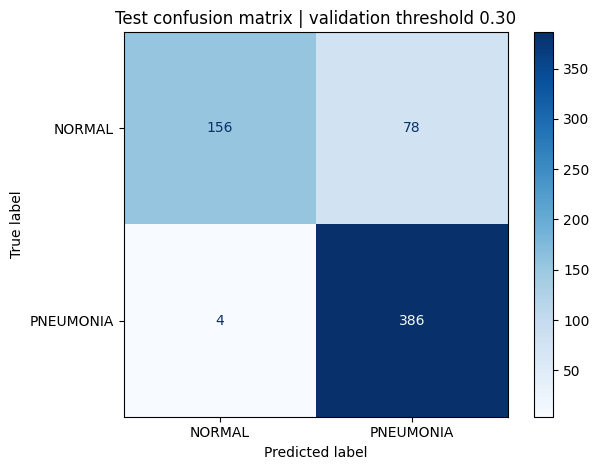

326

In [ ]:
# Test inference begins only after the validation policy has been saved.
saved_policy = json.loads((RUN_DIR / 'threshold_policy.json').read_text())
assert saved_policy['status'] == 'locked_before_test'
assert DECISION_THRESHOLD == saved_policy['decision_threshold']
y_true, y_prob = collect_predictions(test_ds)
assert len(y_true) == len(test_file_paths)
assert np.array_equal(y_true, [class_names.index(Path(p).parent.name) for p in test_file_paths])
y_pred = (y_prob >= DECISION_THRESHOLD).astype(int)
test_metrics = threshold_metrics(y_true, y_prob, DECISION_THRESHOLD)
test_metrics.update(roc_auc=float(roc_auc_score(y_true, y_prob)), n=int(len(y_true)),
    threshold_source='internal_validation', test_previously_inspected=True)
test_report = classification_report(y_true, y_pred, labels=[0, 1],
    target_names=class_names, digits=4, zero_division=0)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
print(f'TEST | fixed validation threshold = {DECISION_THRESHOLD:.2f}')
print('Historical limitation: this test set was inspected in earlier versions.')
print(test_report)
print(json.dumps(test_metrics, indent=2))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues')
plt.title(f'Test confusion matrix | validation threshold {DECISION_THRESHOLD:.2f}')
plt.tight_layout()
plt.savefig(RUN_DIR / 'test_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()
pd.DataFrame({'file': split_manifest['files']['test'], 'y_true': y_true,
    'p_pneumonia': y_prob, 'y_pred': y_pred}).to_csv(RUN_DIR / 'test_predictions.csv', index=False)
(RUN_DIR / 'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))
(RUN_DIR / 'classification_report.txt').write_text(test_report)

In [ ]:
import cv2

def load_image_for_prediction(img_path):
    # Identical decode and bilinear resize to the evaluation pipeline.
    image = tf.io.decode_image(tf.io.read_file(str(img_path)), channels=3, expand_animations=False)
    return tf.image.resize(image, IMG_SIZE, method='bilinear')[tf.newaxis, ...]

def make_gradcam_heatmap(img_array, model, decision_threshold, last_conv_layer_name='last_conv_features'):
    grad_model = tf.keras.Model(model.inputs,
        [model.get_layer(last_conv_layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array, training=False)
        pneumonia_score = predictions[:, 0]
        score = tf.where(pneumonia_score >= decision_threshold, pneumonia_score, 1.0 - pneumonia_score)
    grads = tape.gradient(score, conv_outputs)
    if grads is None:
        raise RuntimeError('Grad-CAM gradients are disconnected.')
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.squeeze(conv_outputs[0] @ pooled_grads[..., tf.newaxis])
    heatmap = tf.maximum(heatmap, 0)
    return (heatmap / (tf.reduce_max(heatmap) + 1e-8)).numpy()

def display_gradcam(img_path, model, decision_threshold, alpha=0.30, heatmap_cutoff=0.0):
    assert decision_threshold == DECISION_THRESHOLD, 'Use the locked classification threshold.'
    assert 0 <= alpha <= 1 and 0 <= heatmap_cutoff <= 1
    img_array = load_image_for_prediction(img_path)
    pneumonia_score = float(model(img_array, training=False).numpy()[0, 0])
    predicted_class = class_names[int(pneumonia_score >= decision_threshold)]
    heatmap = make_gradcam_heatmap(img_array, model, decision_threshold)
    heatmap = cv2.resize(heatmap, IMG_SIZE)
    # Display cutoff affects heatmap visibility only, never the class decision.
    visible = heatmap >= heatmap_cutoff
    masked_heatmap = np.where(visible, heatmap, 0)
    image = np.clip(img_array.numpy()[0], 0, 255).astype(np.uint8)
    colors = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * masked_heatmap), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    blended = (1 - alpha) * image.astype(np.float32) + alpha * colors.astype(np.float32)
    overlay = np.where(visible[..., None], np.clip(blended, 0, 255), image).astype(np.uint8)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(image)
    axes[0].set_title(f'Original | true: {Path(img_path).parent.name}')
    axes[1].imshow(masked_heatmap, cmap='jet', vmin=0, vmax=1)
    axes[1].set_title(f'Grad-CAM | display cutoff {heatmap_cutoff:.2f}')
    axes[2].imshow(overlay)
    axes[2].set_title(f'Pred: {predicted_class} | score(P)={pneumonia_score:.3f}\nDecision threshold={decision_threshold:.2f}')
    for ax in axes:
        ax.axis('off')
    fig.tight_layout()
    output_name = Path(img_path).stem + f'_gradcam_cutoff_{heatmap_cutoff:.2f}.png'
    fig.savefig(RUN_DIR / output_name, dpi=140, bbox_inches='tight')
    plt.show()

Image: IM-0001-0001.jpeg


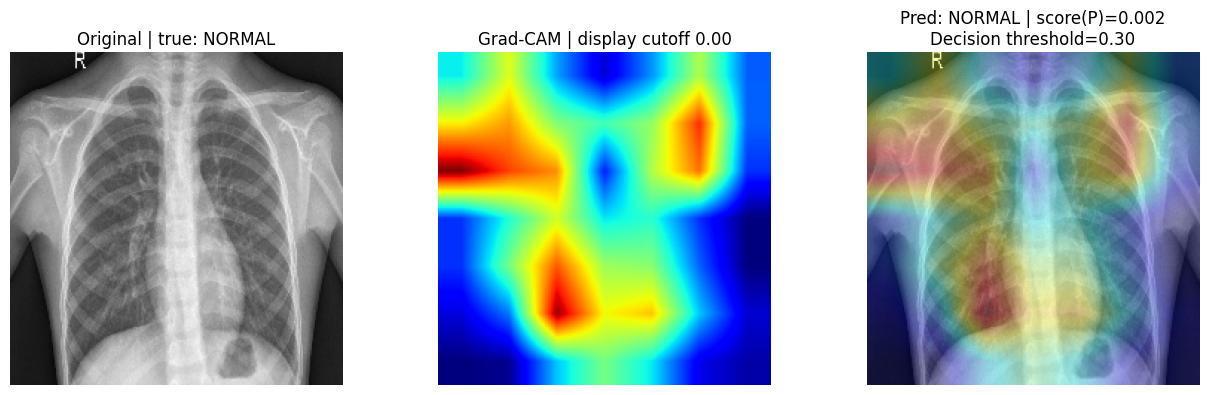

Image: person100_bacteria_475.jpeg


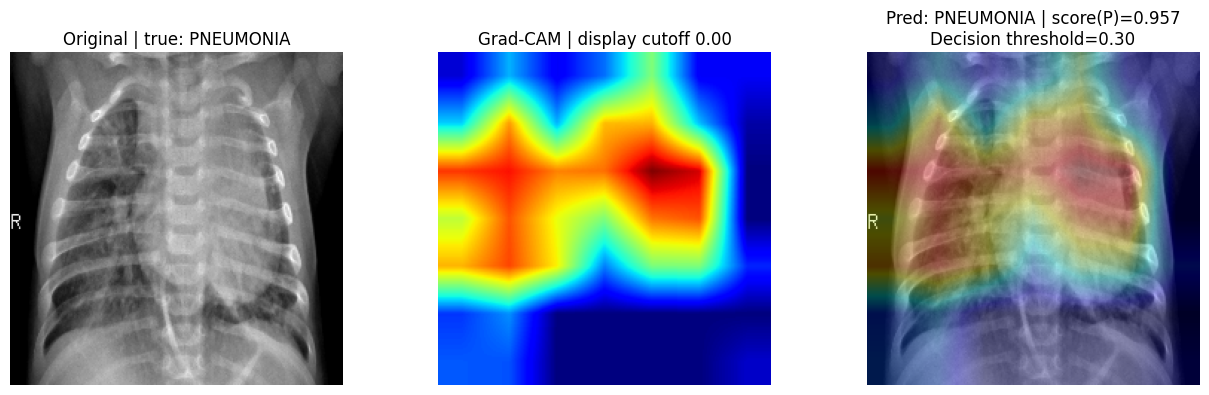

In [ ]:
# Fixed first example from each class; no search for visually attractive results.
normal_images = sorted(p for p in test_file_paths if Path(p).parent.name == 'NORMAL')
pneumonia_images = sorted(p for p in test_file_paths if Path(p).parent.name == 'PNEUMONIA')
sample_images = [normal_images[0], pneumonia_images[0]]
for img_path in sample_images:
    print('Image:', Path(img_path).name)
    display_gradcam(img_path, model, DECISION_THRESHOLD)

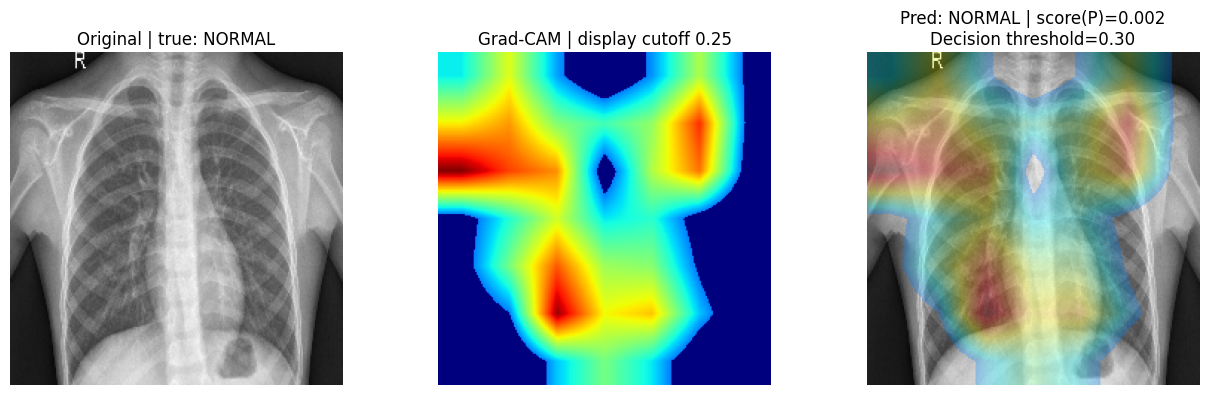

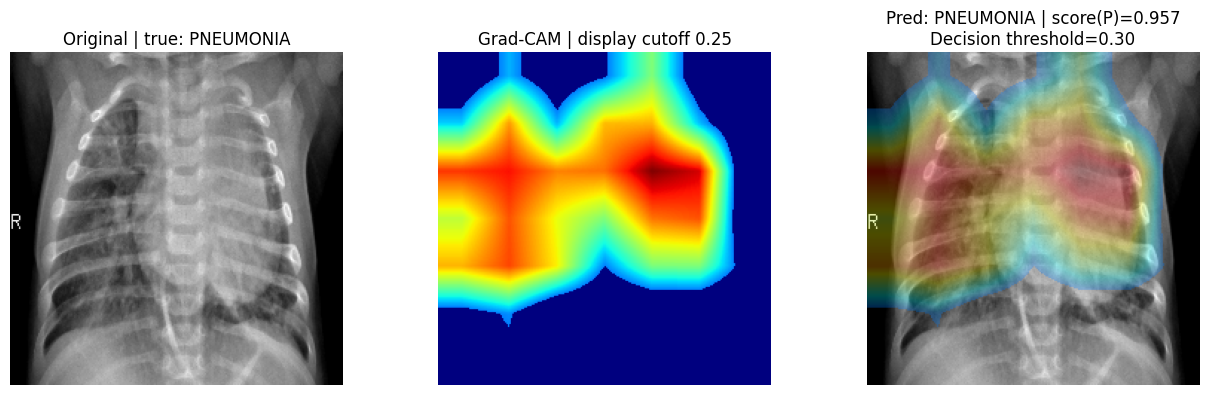

In [ ]:
def display_gradcam_clean(img_path, model, decision_threshold, alpha=0.30, heatmap_cutoff=0.25):
    # heatmap_cutoff is a visual intensity cutoff, not a classification threshold.
    return display_gradcam(img_path, model, decision_threshold, alpha, heatmap_cutoff)

for img_path in sample_images:
    display_gradcam_clean(img_path, model, DECISION_THRESHOLD)

In [ ]:
tn_indices = np.flatnonzero((y_true == 0) & (y_pred == 0))
tp_indices = np.flatnonzero((y_true == 1) & (y_pred == 1))
fp_indices = np.flatnonzero((y_true == 0) & (y_pred == 1))
fn_indices = np.flatnonzero((y_true == 1) & (y_pred == 0))
print('Error analysis at locked threshold:', DECISION_THRESHOLD)
for name, indices in [('TN', tn_indices), ('TP', tp_indices), ('FP', fp_indices), ('FN', fn_indices)]:
    print(name, len(indices))

Error analysis at locked threshold: 0.3
TN 156
TP 386
FP 78
FN 4


TN IM-0001-0001.jpeg


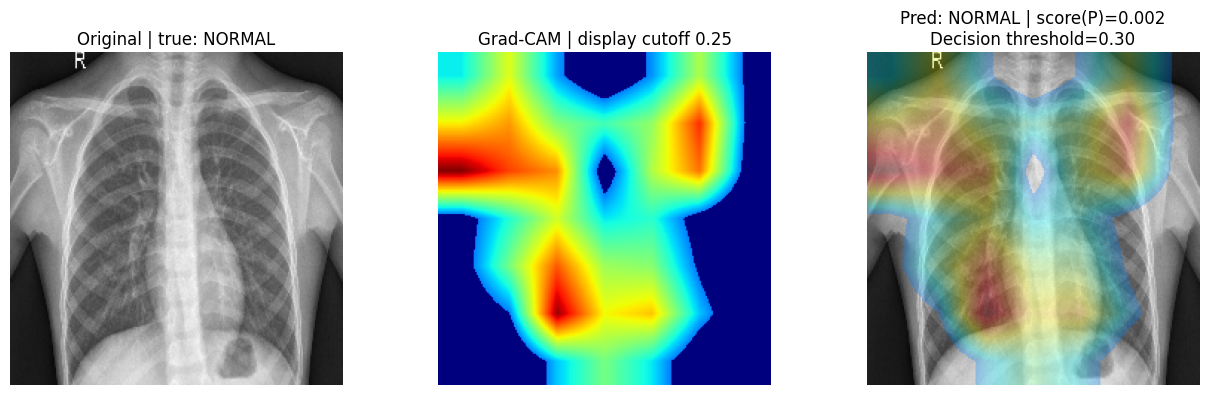

TP person100_bacteria_475.jpeg


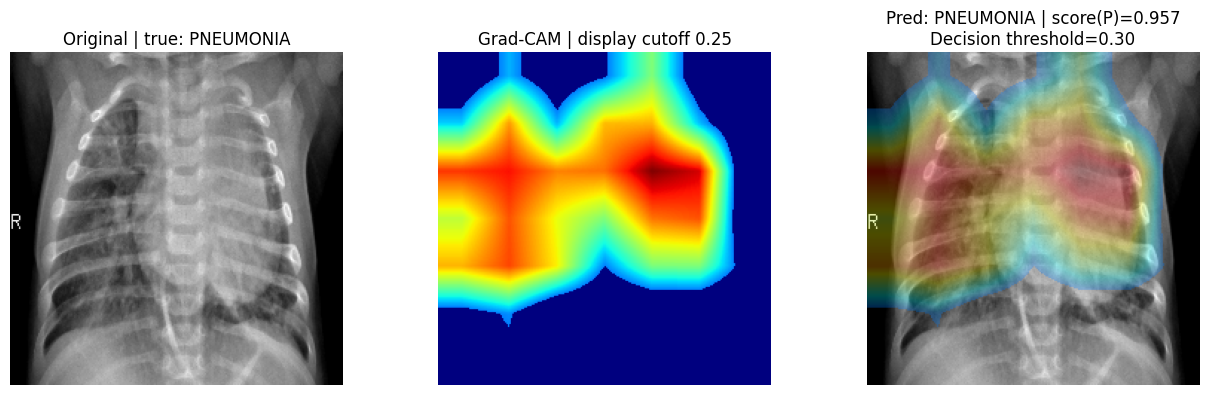

FP IM-0022-0001.jpeg


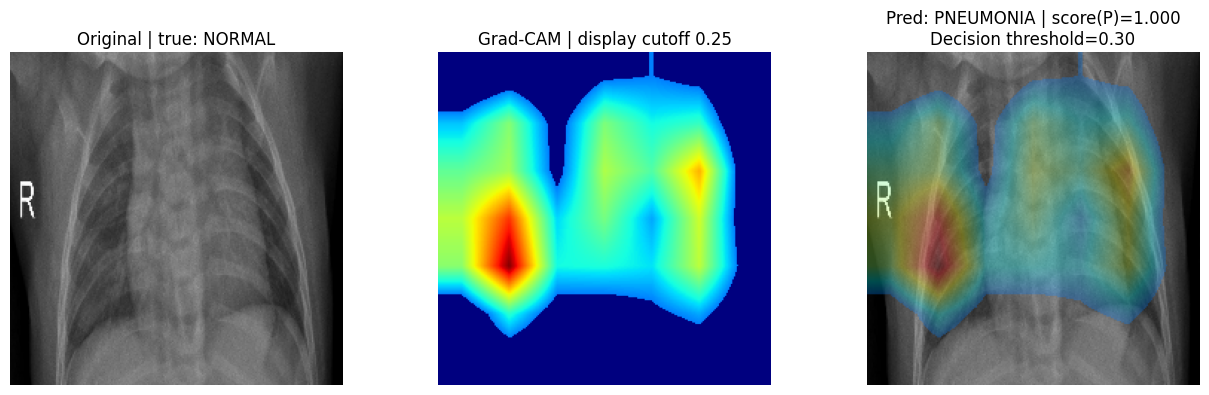

FN person108_bacteria_511.jpeg


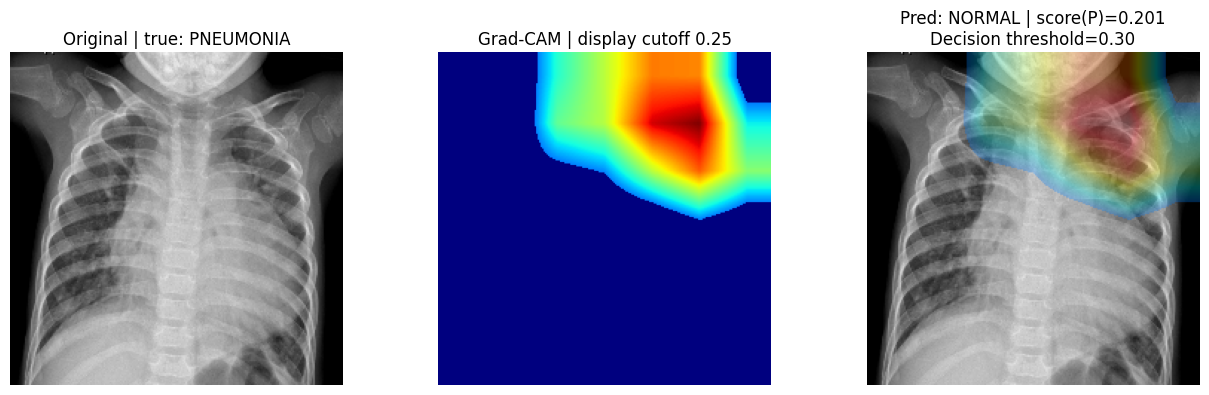

In [ ]:
# Illustrative first case in file order, not a representative or exhaustive explanation.
for name, indices in [('TN', tn_indices), ('TP', tp_indices), ('FP', fp_indices), ('FN', fn_indices)]:
    if len(indices) == 0:
        print(f'{name}: no example at the locked threshold.')
        continue
    img_path = test_file_paths[indices[0]]
    print(name, Path(img_path).name)
    display_gradcam_clean(img_path, model, DECISION_THRESHOLD)

In [ ]:
print('VALIDATION threshold analysis (not test):')
display(validation_threshold_df.round(4))
print('Selected using unrounded metrics:', DECISION_THRESHOLD)
display(eligible.head(1).round(4))

VALIDATION threshold analysis (not test):


,threshold,accuracy,precision,recall,f1,true_negative,false_positive,false_negative,true_positive
0,0.30,0.9706,0.9897,0.9713,0.9804,184,6,17,575
1,0.35,0.9668,0.9896,0.9662,0.9778,184,6,20,572
2,0.40,0.9642,0.9896,0.9628,0.9760,184,6,22,570
3,0.45,0.9629,0.9896,0.9611,0.9751,184,6,23,569
4,0.50,0.9604,0.9895,0.9578,0.9734,184,6,25,567
5,0.55,0.9591,0.9895,0.9561,0.9725,184,6,26,566
6,0.60,0.9552,0.9895,0.9510,0.9699,184,6,29,563
7,0.65,0.9501,0.9911,0.9426,0.9662,185,5,34,558
8,0.70,0.9476,0.9911,0.9392,0.9644,185,5,36,556
9,0.75,0.9437,0.9928,0.9324,0.9617,186,4,40,552


Selected using unrounded metrics: 0.3


,threshold,accuracy,precision,recall,f1,true_negative,false_positive,false_negative,true_positive
0,0.3,0.9706,0.9897,0.9713,0.9804,184,6,17,575


In [ ]:
# Consistency checks use the stored predictions; no threshold is tuned here.
assert np.array_equal(y_pred, (y_prob >= DECISION_THRESHOLD).astype(int))
assert int(cm.sum()) == len(y_true)
assert (len(tn_indices), len(fp_indices), len(fn_indices), len(tp_indices)) == (
    test_metrics['true_negative'], test_metrics['false_positive'],
    test_metrics['false_negative'], test_metrics['true_positive'])
assert json.loads((RUN_DIR / 'threshold_policy.json').read_text())['decision_threshold'] == DECISION_THRESHOLD
print('Threshold, predictions, confusion matrix and error counts are consistent.')

Threshold, predictions, confusion matrix and error counts are consistent.


In [ ]:
# Save one generated summary; do not copy metrics from earlier project versions.
summary = f"""# Chest X-Ray Pneumonia - Corrected Run

Decision threshold: {DECISION_THRESHOLD:.2f}, selected on internal validation.
Selection rule: precision >= {PRECISION_TARGET:.2f}; maximize recall, then F1, then lower threshold.
Test size: {len(y_true)} images.
Test accuracy: {test_metrics['accuracy']:.6f}
Test pneumonia precision: {test_metrics['precision']:.6f}
Test pneumonia recall: {test_metrics['recall']:.6f}
Test pneumonia F1: {test_metrics['f1']:.6f}
Test ROC-AUC: {test_metrics['roc_auc']:.6f}
Confusion matrix [[TN, FP], [FN, TP]]: {cm.tolist()}

The test set was inspected in earlier versions; these are not results on a new unseen test.
The internal split is image-level; patient independence and duplicate separation are unverified.
Research/educational prototype. Grad-CAM is qualitative. Scores are uncalibrated.
"""
(RUN_DIR / 'RUN_SUMMARY.md').write_text(summary)
print(summary)

# Chest X-Ray Pneumonia - Corrected Run

Decision threshold: 0.30, selected on internal validation.
Selection rule: precision >= 0.90; maximize recall, then F1, then lower threshold.
Test size: 624 images.
Test accuracy: 0.868590
Test pneumonia precision: 0.831897
Test pneumonia recall: 0.989744
Test pneumonia F1: 0.903981
Test ROC-AUC: 0.966963
Confusion matrix [[TN, FP], [FN, TP]]: [[156, 78], [4, 386]]

The test set was inspected in earlier versions; these are not results on a new unseen test.
The internal split is image-level; patient independence and duplicate separation are unverified.
Research/educational prototype. Grad-CAM is qualitative. Scores are uncalibrated.



In [ ]:
import hashlib
import shutil
import sklearn

assert MODEL_PATH.exists(), 'The fitted model must have been saved before test inference.'
restored_model = tf.keras.models.load_model(MODEL_PATH, compile=False)
check_images, _ = next(iter(val_ds.take(1)))
original_scores = np.asarray(model(check_images, training=False))
restored_scores = np.asarray(restored_model(check_images, training=False))
np.testing.assert_allclose(original_scores, restored_scores, rtol=1e-5, atol=1e-6)
reload_max_error = float(np.max(np.abs(original_scores - restored_scores)))
print('Saved model reload verified. Maximum score difference:', reload_max_error)
model_sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
environment = {'python': platform.python_version(), 'tensorflow': tf.__version__,
    'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__,
    'kagglehub': getattr(kagglehub, '__version__', 'unknown'), 'seed': SEED,
    'dataset_handle': DATASET_HANDLE, 'dataset_cache': str(dataset_root),
    'model_sha256': model_sha256, 'decision_threshold': DECISION_THRESHOLD,
    'model_reload_max_abs_error': reload_max_error}
(RUN_DIR / 'environment.json').write_text(json.dumps(environment, indent=2))
threshold_policy['model_sha256'] = model_sha256
(RUN_DIR / 'threshold_policy.json').write_text(json.dumps(threshold_policy, indent=2))
archive_path = shutil.make_archive(str(RUN_DIR), 'zip', root_dir=RUN_DIR)
print('Model, threshold policy, split manifest, predictions, metrics and figures saved.')
print('Run directory:', RUN_DIR)
print('Downloadable archive:', archive_path)
print('Decision threshold:', DECISION_THRESHOLD)
print('Preserve the archive outside this temporary Colab runtime.')

Saved model reload verified. Maximum score difference: 0.0
Model, threshold policy, split manifest, predictions, metrics and figures saved.
Run directory: /content/pneumonia_runs/20261022T065237_860984Z
Downloadable archive: /content/pneumonia_runs/20261022T065237_860984Z.zip
Decision threshold: 0.3
Preserve the archive outside this temporary Colab runtime.


In [ ]:
# V3 development audit. No new test predictions are computed here.
import re
import hashlib
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

def filename_group(path):
    name = Path(path).name
    person = re.match(r'person(\d+)_', name, flags=re.I)
    if person:
        return 'pneumonia_person_' + person.group(1)
    normal = re.match(r'(NORMAL2-)?IM-(\d+)-', name, flags=re.I)
    if normal:
        return ('normal2_' if normal.group(1) else 'normal1_') + normal.group(2)
    return 'unparsed_' + Path(path).stem

prior_train_groups = {filename_group(p) for p in train_paths}
prior_val_groups = {filename_group(p) for p in val_paths}
all_source_train = sorted(set(train_paths) | set(val_paths))
def file_digest(path):
    return str(path), hashlib.sha256(Path(path).read_bytes()).hexdigest()
with ThreadPoolExecutor(max_workers=8) as pool:
    train_digest_map = dict(pool.map(file_digest, all_source_train))
prior_train_hashes = {train_digest_map[str(p)] for p in train_paths}
prior_val_hashes = {train_digest_map[str(p)] for p in val_paths}
v3_audit = {
    'prior_train_images': len(train_paths), 'prior_validation_images': len(val_paths),
    'filename_proxy_groups_shared_train_validation': len(prior_train_groups & prior_val_groups),
    'byte_identical_hashes_shared_train_validation': len(prior_train_hashes & prior_val_hashes),
    'unique_source_training_images': len(all_source_train),
    'unique_source_training_hashes': len(set(train_digest_map.values())),
    'filename_proxy_group_count': len({filename_group(p) for p in all_source_train}),
    'unparsed_names': [Path(p).name for p in all_source_train if filename_group(p).startswith('unparsed_')],
    'scope': 'Filename keys are grouping proxies; they do not verify clinical patient identity.'
}
(RUN_DIR / 'v3_development_audit.json').write_text(json.dumps(v3_audit, indent=2))
print(json.dumps(v3_audit, indent=2))


{
  "prior_train_images": 4434,
  "prior_validation_images": 782,
  "filename_proxy_groups_shared_train_validation": 409,
  "byte_identical_hashes_shared_train_validation": 7,
  "unique_source_training_images": 5216,
  "unique_source_training_hashes": 5190,
  "filename_proxy_group_count": 2846,
  "unparsed_names": [],
  "scope": "Filename keys are grouping proxies; they do not verify clinical patient identity."
}


In [ ]:
# V3: fixed development protocol, written before training candidates or scoring the historical test.
from sklearn.model_selection import StratifiedGroupKFold
import time
import gc

V3_DIR = Path('/content/pneumonia_v3') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
V3_DIR.mkdir(parents=True, exist_ok=False)
V3_CONFIG = {
    'seed': 42, 'image_size': [224, 224], 'batch_size': 24,
    'head_epochs': 6, 'fine_tune_epochs': 12,
    'head_lr': 0.001, 'fine_tune_lr': 0.00002,
    'label_smoothing': 0.02, 'dropout': 0.35, 'normal_weight_multiplier': 1.25,
    'precision_floor': 0.95, 'recall_floor': 0.95,
    'threshold_grid': np.round(np.arange(1, 100) / 100, 2).tolist(),
    'selection_rule': 'require validation precision and recall >= 0.95; maximize specificity, then F1, then higher threshold; model ties use ROC-AUC then model name',
    'candidate_models': ['MobileNetV2', 'DenseNet121', 'EfficientNetB0'],
    'fixed_ensembles': [['DenseNet121', 'EfficientNetB0'], ['MobileNetV2', 'DenseNet121', 'EfficientNetB0']],
    'validation_split_rule': 'StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42), first fold only',
    'grouping': 'Connected components of filename person/study proxies and SHA-256 duplicates',
    'test_status': 'Historical benchmark already inspected; current development request is informed by its earlier results. No claim of independent unseen testing.',
    'stop_rule': 'Train the three predeclared candidates, compare the two fixed means on validation, lock one candidate and threshold, score historical test once; do not retune from that score.'
}
(V3_DIR / 'development_protocol.json').write_text(json.dumps(V3_CONFIG, indent=2))
(V3_DIR / 'prior_split_audit.json').write_text(json.dumps(v3_audit, indent=2))

# Test files are checked for identity/group separation only, without model predictions.
with ThreadPoolExecutor(max_workers=8) as pool:
    v3_test_digests = dict(pool.map(file_digest, test_file_paths))
v3_test_hashes = set(v3_test_digests.values())
v3_test_groups = {filename_group(p) for p in test_file_paths}

# Merge proxy groups connected by byte-identical source-training images.
parent = {filename_group(p): filename_group(p) for p in all_source_train}
def root_group(group):
    while parent[group] != group:
        parent[group] = parent[parent[group]]
        group = parent[group]
    return group
def union_groups(a, b):
    a, b = root_group(a), root_group(b)
    if a != b:
        parent[max(a, b)] = min(a, b)
hash_first = {}
for p in all_source_train:
    digest = train_digest_map[p]
    if digest in hash_first:
        assert Path(p).parent.name == Path(hash_first[digest]).parent.name, 'Conflicting labels on an exact duplicate.'
        union_groups(filename_group(p), filename_group(hash_first[digest]))
    else:
        hash_first[digest] = p
excluded_components = {root_group(filename_group(p)) for p in all_source_train
    if filename_group(p) in v3_test_groups or train_digest_map[p] in v3_test_hashes}
v3_pool = []
v3_removed = []
seen_hashes = set()
for p in all_source_train:
    digest = train_digest_map[p]
    if root_group(filename_group(p)) in excluded_components:
        v3_removed.append({'file': str(Path(p).relative_to(base_dir)), 'reason': 'historical_test_identity_or_proxy_group'})
    elif digest in seen_hashes:
        v3_removed.append({'file': str(Path(p).relative_to(base_dir)), 'reason': 'duplicate_within_source_training'})
    else:
        seen_hashes.add(digest)
        v3_pool.append(p)
v3_pool = np.array(v3_pool)
v3_labels = np.array([class_names.index(Path(p).parent.name) for p in v3_pool])
v3_groups = np.array([root_group(filename_group(p)) for p in v3_pool])
v3_fit_idx, v3_dev_idx = next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42).split(v3_pool, v3_labels, v3_groups))
v3_fit_paths = v3_pool[v3_fit_idx].tolist()
v3_dev_paths = v3_pool[v3_dev_idx].tolist()
assert not (set(v3_groups[v3_fit_idx]) & set(v3_groups[v3_dev_idx]))
assert not ({train_digest_map[p] for p in v3_fit_paths} & {train_digest_map[p] for p in v3_dev_paths})
assert not ({train_digest_map[p] for p in v3_fit_paths + v3_dev_paths} & v3_test_hashes)
v3_manifest = {'protocol': V3_CONFIG, 'class_names': class_names, 'removed': v3_removed,
    'files': {s: [str(Path(p).relative_to(base_dir)) for p in paths] for s, paths in
        [('train', v3_fit_paths), ('validation', v3_dev_paths), ('historical_test', test_file_paths)]},
    'group_keys': {s: [root_group(filename_group(p)) for p in paths] for s, paths in
        [('train', v3_fit_paths), ('validation', v3_dev_paths)]},
    'hashes': {str(Path(p).relative_to(base_dir)): train_digest_map[str(p)] for p in v3_pool}}
(V3_DIR / 'split_manifest.json').write_text(json.dumps(v3_manifest, indent=2))
print('V3 run directory:', V3_DIR)
print('V3 train/validation/historical-test:', len(v3_fit_paths), len(v3_dev_paths), len(test_file_paths))
print('V3 removed source images:', Counter(r['reason'] for r in v3_removed))
print('V3 training counts:', Counter(v3_labels[v3_fit_idx]))
print('V3 validation counts:', Counter(v3_labels[v3_dev_idx]))
print('Group-proxy and exact-byte separation checks passed. Near-duplicates and clinical patient identity remain unverified.')

V3_BATCH = V3_CONFIG['batch_size']
def v3_ordered_dataset(paths):
    labels = np.array([class_names.index(Path(p).parent.name) for p in paths], dtype=np.float32)
    def decode(path, label):
        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        return tf.image.resize(image, (224, 224), method='bilinear'), tf.reshape(label, (1,))
    return tf.data.Dataset.from_tensor_slices((list(paths), labels)).map(decode,
        num_parallel_calls=tf.data.AUTOTUNE, deterministic=True).batch(V3_BATCH)

v3_fit_ordered = v3_ordered_dataset(v3_fit_paths).unbatch().cache()
v3_dev_ds = v3_ordered_dataset(v3_dev_paths).cache().prefetch(tf.data.AUTOTUNE)
v3_dev_y = np.array([class_names.index(Path(p).parent.name) for p in v3_dev_paths])
v3_counts = Counter(v3_labels[v3_fit_idx])
v3_weights = {c: len(v3_fit_paths) / (2 * count) for c, count in v3_counts.items()}
v3_weights[0] *= V3_CONFIG['normal_weight_multiplier']
v3_grid = np.array(V3_CONFIG['threshold_grid'])
v3_records = {}
print('Fixed V3 class weights:', v3_weights)
print('No candidate test predictions have been computed.')


V3 run directory: /content/pneumonia_v3/20261022T071741_996877Z
V3 train/validation/historical-test: 4056 681 624
V3 removed source images: Counter({'historical_test_identity_or_proxy_group': 457, 'duplicate_within_source_training': 22})
V3 training counts: Counter({np.int64(1): 2900, np.int64(0): 1156})
V3 validation counts: Counter({np.int64(1): 497, np.int64(0): 184})
Group-proxy and exact-byte separation checks passed. Near-duplicates and clinical patient identity remain unverified.
Fixed V3 class weights: {np.int64(0): 2.192906574394464, np.int64(1): 0.6993103448275862}
No candidate test predictions have been computed.


In [ ]:
# Model construction and validation-only checkpoint selection.
from tensorflow.keras import layers
tf.keras.mixed_precision.set_global_policy('mixed_float16')

def v3_metrics(truth, probabilities, threshold):
    prediction = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
    return {'threshold': float(threshold), 'accuracy': float((tn + tp) / len(truth)),
        'precision': float(tp / (tp + fp)) if tp + fp else 0.0,
        'recall': float(tp / (tp + fn)), 'specificity': float(tn / (tn + fp)),
        'f1': float(2 * tp / (2 * tp + fp + fn)) if 2 * tp + fp + fn else 0.0,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}

def v3_policy_for(probabilities):
    rows = [v3_metrics(v3_dev_y, probabilities, t) for t in v3_grid]
    feasible = [r for r in rows if r['precision'] >= V3_CONFIG['precision_floor'] and r['recall'] >= V3_CONFIG['recall_floor']]
    if feasible:
        best = sorted(feasible, key=lambda r: (-r['specificity'], -r['f1'], -r['threshold']))[0]
        best['constraints_met'] = True
    else:
        # This only ranks checkpoints for diagnostic retention; final selection still stops if no candidate is feasible.
        best = sorted(rows, key=lambda r: (-r['f1'], -r['specificity'], -r['threshold']))[0]
        best['constraints_met'] = False
    best['roc_auc'] = float(roc_auc_score(v3_dev_y, probabilities))
    return best

def v3_predict(model, dataset):
    return np.concatenate([np.asarray(model(images, training=False)).ravel() for images, _ in dataset])

class V3DevCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, name):
        super().__init__()
        self.name = name
        self.best_key = None
        self.best_metrics = None
        self.rows = []
        self.phase = 'head'
        self.path = V3_DIR / f'{name}_best.weights.h5'
    def on_epoch_end(self, epoch, logs=None):
        probabilities = v3_predict(self.model, v3_dev_ds)
        result = v3_policy_for(probabilities)
        key = (int(result['constraints_met']), result['specificity'] if result['constraints_met'] else result['f1'], result['f1'], result['roc_auc'])
        result.update(model=self.name, phase=self.phase, epoch=int(epoch + 1))
        self.rows.append(dict(result))
        if self.best_key is None or key > self.best_key:
            self.best_key, self.best_metrics = key, dict(result)
            self.model.save_weights(self.path)
            np.save(V3_DIR / f'{self.name}_validation_probabilities.npy', probabilities)
        print(f" | {self.name} validation checkpoint: spec={result['specificity']:.4f}, precision={result['precision']:.4f}, recall={result['recall']:.4f}, feasible={result['constraints_met']}")
        pd.DataFrame(self.rows).to_csv(V3_DIR / f'{self.name}_epoch_selection.csv', index=False)

def v3_build(name):
    inputs = layers.Input((224, 224, 3), name=f'{name}_image')
    augmentation = tf.keras.Sequential([
        layers.RandomRotation(0.03, fill_mode='reflect', seed=42),
        layers.RandomTranslation(0.04, 0.04, fill_mode='reflect', seed=43),
        layers.RandomZoom(0.08, fill_mode='reflect', seed=44),
        layers.RandomBrightness(0.15, value_range=(0, 255), seed=45),
        layers.RandomContrast(0.15, seed=46)
    ], name=f'{name}_augmentation')
    x = augmentation(inputs)
    if name == 'MobileNetV2':
        backbone = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(224, 224, 3), name='v3_mobilenetv2')
        x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
        unfreeze = 60
    elif name == 'DenseNet121':
        backbone = tf.keras.applications.DenseNet121(include_top=False, weights='imagenet', input_shape=(224, 224, 3), name='v3_densenet121')
        x = tf.keras.applications.densenet.preprocess_input(x)
        unfreeze = 140
    elif name == 'EfficientNetB0':
        # Keep the standard backbone name: this Keras version derives its pretrained-weight filename from it.
        backbone = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
        # EfficientNet embeds its own pixel rescaling. Input remains 0..255.
        unfreeze = 80
    else:
        raise ValueError(name)
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.Activation('linear', name='last_conv_features')(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(V3_CONFIG['dropout'], seed=47)(x)
    outputs = layers.Dense(1, activation='sigmoid', dtype='float32', name='prediction')(x)
    return tf.keras.Model(inputs, outputs, name=f'v3_{name}'), backbone, unfreeze

def v3_compile(candidate, lr):
    candidate.compile(optimizer=tf.keras.optimizers.Adam(lr),
        loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=V3_CONFIG['label_smoothing']),
        metrics=[tf.keras.metrics.AUC(name='auc'), tf.keras.metrics.BinaryAccuracy(name='accuracy')])

def v3_train_candidate(name):
    assert name in V3_CONFIG['candidate_models']
    started = time.time()
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(42)
    candidate, backbone, unfreeze = v3_build(name)
    train_data = v3_fit_ordered.shuffle(min(2000, len(v3_fit_paths)), seed=42,
        reshuffle_each_iteration=True).batch(V3_BATCH).apply(tf.data.experimental.assert_cardinality(
        (len(v3_fit_paths) + V3_BATCH - 1) // V3_BATCH)).prefetch(tf.data.AUTOTUNE)
    checkpoint = V3DevCheckpoint(name)
    def callbacks():
        return [checkpoint, tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=False),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7)]
    v3_compile(candidate, V3_CONFIG['head_lr'])
    print('\nTRAINING', name, 'HEAD')
    candidate.fit(train_data, validation_data=v3_dev_ds, epochs=V3_CONFIG['head_epochs'],
        class_weight=v3_weights, callbacks=callbacks(), verbose=2)
    candidate.load_weights(checkpoint.path)
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = False
    for layer in backbone.layers[-unfreeze:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True
    checkpoint.phase = 'fine_tune'
    v3_compile(candidate, V3_CONFIG['fine_tune_lr'])
    print('\nTRAINING', name, 'FINE-TUNE; BatchNormalization remains frozen')
    candidate.fit(train_data, validation_data=v3_dev_ds, epochs=V3_CONFIG['fine_tune_epochs'],
        class_weight=v3_weights, callbacks=callbacks(), verbose=2)
    candidate.load_weights(checkpoint.path)
    probabilities = v3_predict(candidate, v3_dev_ds)
    result = v3_policy_for(probabilities)
    # Export an inference model without optimizer state.
    inference = tf.keras.Model(candidate.inputs, candidate.outputs, name=candidate.name)
    path = V3_DIR / f'{name}.keras'
    inference.save(path)
    restored = tf.keras.models.load_model(path, compile=False)
    restored_probabilities = v3_predict(restored, v3_dev_ds)
    np.testing.assert_allclose(probabilities, restored_probabilities, atol=1e-5, rtol=1e-4)
    pd.DataFrame({'file': v3_manifest['files']['validation'], 'y_true': v3_dev_y,
        'p_pneumonia': restored_probabilities}).to_csv(V3_DIR / f'{name}_validation_predictions.csv', index=False)
    result.update(name=name, members=[name], model_file=str(path), elapsed_seconds=time.time() - started,
        selected_checkpoint=checkpoint.best_metrics, reload_max_abs_error=float(np.max(np.abs(probabilities - restored_probabilities))))
    v3_records[name] = result
    (V3_DIR / 'candidate_records.json').write_text(json.dumps(v3_records, indent=2))
    print('CANDIDATE COMPLETE', json.dumps(result, indent=2))
    del candidate, inference, restored, backbone, train_data
    gc.collect()
    return result

print('Three candidate definitions are ready. All checkpoint decisions use grouped validation only.')


Three candidate definitions are ready. All checkpoint decisions use grouped validation only.


In [ ]:
v3_mobile_result = v3_train_candidate('MobileNetV2')



TRAINING MobileNetV2 HEAD
Epoch 1/6
 | MobileNetV2 validation checkpoint: spec=0.9620, precision=0.9855, recall=0.9598, feasible=True
169/169 - 26s - 156ms/step - accuracy: 0.8185 - auc: 0.9176 - loss: 0.4213 - val_accuracy: 0.9530 - val_auc: 0.9904 - val_loss: 0.1906 - learning_rate: 0.0010
Epoch 2/6
 | MobileNetV2 validation checkpoint: spec=0.9837, precision=0.9937, recall=0.9517, feasible=True
169/169 - 14s - 82ms/step - accuracy: 0.9036 - auc: 0.9734 - loss: 0.2725 - val_accuracy: 0.9692 - val_auc: 0.9938 - val_loss: 0.1566 - learning_rate: 0.0010
Epoch 3/6
 | MobileNetV2 validation checkpoint: spec=0.9837, precision=0.9937, recall=0.9577, feasible=True
169/169 - 14s - 82ms/step - accuracy: 0.9253 - auc: 0.9808 - loss: 0.2395 - val_accuracy: 0.9677 - val_auc: 0.9942 - val_loss: 0.1540 - learning_rate: 0.0010
Epoch 4/6
 | MobileNetV2 validation checkpoint: spec=0.9837, precision=0.9937, recall=0.9557, feasible=True
169/169 - 13s - 79ms/step - accuracy: 0.9312 - auc: 0.9838 - loss:

In [ ]:
v3_dense_result = v3_train_candidate('DenseNet121')


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

TRAINING DenseNet121 HEAD
Epoch 1/6
 | DenseNet121 validation checkpoint: spec=0.9185, precision=0.9693, recall=0.9537, feasible=True
169/169 - 56s - 329ms/step - accuracy: 0.7073 - auc: 0.8100 - loss: 0.6044 - val_accuracy: 0.9442 - val_auc: 0.9840 - val_loss: 0.2371 - learning_rate: 0.0010
Epoch 2/6
 | DenseNet121 validation checkpoint: spec=0.9511, precision=0.9814, recall=0.9537, feasible=True
169/169 - 38s - 226ms/step - accuracy: 0.8580 - auc: 0.9446 - loss: 0.3649 - val_accuracy: 0.9574 - val_auc: 0.9905 - val_loss: 0.1852 - learning_rate: 0.0010
Epoch 3/6
 | DenseNet121 validation checkpoint: spec=0.9565, precision=0.9836, recall=0.9658, feasible=True
169/169 - 39s - 231ms/step - accuracy: 0.8952 - auc: 0.9644 - loss: 0.3042 - val_accuracy: 0.9501 - val_auc: 0.9924 - val_loss: 0.1839 - learning_rate: 0.0010
Epoch 4/6
 | DenseNet121 validation checkpoint: spec=0.9674, precision=0.9876, recall=0.9577, feasible=True
169/169 - 38s

In [ ]:
v3_efficient_result = v3_train_candidate('EfficientNetB0')


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

TRAINING EfficientNetB0 HEAD
Epoch 1/6
 | EfficientNetB0 validation checkpoint: spec=0.8696, precision=0.9518, recall=0.9537, feasible=True
169/169 - 33s - 194ms/step - accuracy: 0.7843 - auc: 0.8867 - loss: 0.4873 - val_accuracy: 0.8855 - val_auc: 0.9765 - val_loss: 0.2940 - learning_rate: 0.0010
Epoch 2/6
 | EfficientNetB0 validation checkpoint: spec=0.9076, precision=0.9653, recall=0.9517, feasible=True
169/169 - 20s - 121ms/step - accuracy: 0.8782 - auc: 0.9598 - loss: 0.3271 - val_accuracy: 0.9192 - val_auc: 0.9839 - val_loss: 0.2391 - learning_rate: 0.0010
Epoch 3/6
 | EfficientNetB0 validation checkpoint: spec=0.9185, precision=0.9695, recall=0.9577, feasible=True
169/169 - 20s - 120ms/step - accuracy: 0.9115 - auc: 0.9745 - loss: 0.2683 - val_accuracy: 0.9325 - val_auc: 0.9867 - val_loss: 0.2177 - learning_rate: 0.0010
Epoch 4/6
 | EfficientNetB0 validation checkpoint: spec=0.9293, precision=0.9733, recall=0.9517, feasible=Tru

In [ ]:
# Compare only predeclared candidates on the SAME grouped validation set.
# A validation-only calibration refinement is recorded BEFORE any V3 benchmark inference:
# use the higher threshold when specificity ties, while preserving both validation floors.
v3_calibration_addendum = {
    'stage': 'after training-validation development, before any V3 historical-test predictions',
    'checkpoint_selection_unchanged': V3_CONFIG['selection_rule'],
    'deployment_threshold_rule': 'validation precision >= 0.95 and recall >= 0.95; maximize specificity, then higher threshold, then F1',
    'model_selection_rule': 'maximize validation specificity, then F1, then ROC-AUC, then model name',
    'reason': 'Avoid favoring a low operating threshold solely for extra recall when validation false-positive counts tie.',
    'uses_current_v3_historical_test_results': False,
    'not_claimed_as_fully_preregistered': True
}
(V3_DIR / 'calibration_addendum.json').write_text(json.dumps(v3_calibration_addendum, indent=2))
def v3_deployment_policy_for(probabilities):
    rows = [v3_metrics(v3_dev_y, probabilities, t) for t in v3_grid]
    feasible = [r for r in rows if r['precision'] >= V3_CONFIG['precision_floor'] and r['recall'] >= V3_CONFIG['recall_floor']]
    best = (sorted(feasible, key=lambda r: (-r['specificity'], -r['threshold'], -r['f1']))[0]
        if feasible else sorted(rows, key=lambda r: (-r['f1'], -r['specificity'], -r['threshold']))[0])
    best.update(constraints_met=bool(feasible), roc_auc=float(roc_auc_score(v3_dev_y, probabilities)))
    return best

v3_probability_bank = {}
for name in V3_CONFIG['candidate_models']:
    frame = pd.read_csv(V3_DIR / f'{name}_validation_predictions.csv')
    assert frame['file'].tolist() == v3_manifest['files']['validation']
    assert np.array_equal(frame['y_true'].to_numpy(), v3_dev_y)
    v3_probability_bank[name] = frame['p_pneumonia'].to_numpy()
    v3_records[name]['checkpoint_operating_point'] = {k: v3_records[name][k] for k in ['threshold', 'precision', 'recall', 'specificity', 'f1']}
    v3_records[name].update(v3_deployment_policy_for(v3_probability_bank[name]))
for members in V3_CONFIG['fixed_ensembles']:
    name = 'Mean_' + '_'.join(members)
    probabilities = np.mean([v3_probability_bank[m] for m in members], axis=0)
    v3_probability_bank[name] = probabilities
    result = v3_deployment_policy_for(probabilities)
    result.update(name=name, members=members, model_file=None)
    v3_records[name] = result
    pd.DataFrame({'file': v3_manifest['files']['validation'], 'y_true': v3_dev_y,
        'p_pneumonia': probabilities}).to_csv(V3_DIR / f'{name}_validation_predictions.csv', index=False)
v3_comparison = pd.DataFrame(v3_records.values())
v3_comparison.drop(columns=['selected_checkpoint'], errors='ignore').to_csv(V3_DIR / 'validation_model_comparison.csv', index=False)
(V3_DIR / 'candidate_records.json').write_text(json.dumps(v3_records, indent=2))
print('GROUPED VALIDATION COMPARISON ONLY')
print(v3_comparison[['name', 'threshold', 'precision', 'recall', 'specificity', 'f1', 'roc_auc', 'constraints_met']].to_string(index=False))
feasible_models = [r for r in v3_records.values() if r['constraints_met']]
if not feasible_models:
    raise RuntimeError('No predeclared candidate meets both validation floors. No historical-test evaluation is authorized by this protocol.')
v3_selected = sorted(feasible_models, key=lambda r: (-r['specificity'], -r['f1'], -r['roc_auc'], r['name']))[0]
V3_THRESHOLD = float(v3_selected['threshold'])
V3_MEMBERS = v3_selected['members']
tf.keras.backend.clear_session()
gc.collect()
v3_member_models = {name: tf.keras.models.load_model(V3_DIR / f'{name}.keras', compile=False) for name in V3_MEMBERS}
if len(V3_MEMBERS) == 1:
    v3_selected_model = v3_member_models[V3_MEMBERS[0]]
else:
    v3_inputs = tf.keras.layers.Input((224, 224, 3), name='ensemble_image')
    v3_outputs = tf.keras.layers.Average(dtype='float32', name='mean_pneumonia_score')([
        v3_member_models[name](v3_inputs, training=False) for name in V3_MEMBERS])
    v3_selected_model = tf.keras.Model(v3_inputs, v3_outputs, name='v3_selected_mean_ensemble')
V3_MODEL_PATH = V3_DIR / 'selected_model.keras'
v3_selected_model.save(V3_MODEL_PATH)
v3_restored_model = tf.keras.models.load_model(V3_MODEL_PATH, compile=False)
v3_reload_probabilities = v3_predict(v3_restored_model, v3_dev_ds)
np.testing.assert_allclose(v3_reload_probabilities, v3_probability_bank[v3_selected['name']], rtol=1e-4, atol=1e-5)
v3_model_hash = hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest()
v3_locked_policy = {
    'status': 'locked_before_current_historical_test_pass', 'selected_candidate': v3_selected['name'],
    'members': V3_MEMBERS, 'decision_threshold': V3_THRESHOLD,
    'comparison': 'P(PNEUMONIA) >= decision_threshold',
    'class_names': class_names, 'selection_dataset': 'grouped_internal_validation',
    'validation_metrics': v3_selected, 'protocol': V3_CONFIG, 'calibration_addendum': v3_calibration_addendum,
    'model_sha256': v3_model_hash,
    'validation_reload_max_abs_error': float(np.max(np.abs(v3_reload_probabilities - v3_probability_bank[v3_selected['name']]))),
    'historical_test_previously_inspected': True,
    'independent_unseen_test': False
}
(V3_DIR / 'locked_policy.json').write_text(json.dumps(v3_locked_policy, indent=2))
print('LOCKED CANDIDATE:', v3_selected['name'])
print('LOCKED THRESHOLD:', V3_THRESHOLD)
print('Model reload and validation prediction parity verified before historical test.')


GROUPED VALIDATION COMPARISON ONLY
                                       name  threshold  precision   recall  specificity       f1  roc_auc  constraints_met
                                MobileNetV2       0.48        1.0 0.951710          1.0 0.975258 0.999267             True
                                DenseNet121       0.65        1.0 0.955734          1.0 0.977366 0.998491             True
                             EfficientNetB0       0.79        1.0 0.951710          1.0 0.975258 0.998721             True
            Mean_DenseNet121_EfficientNetB0       0.70        1.0 0.951710          1.0 0.975258 0.999027             True
Mean_MobileNetV2_DenseNet121_EfficientNetB0       0.67        1.0 0.951710          1.0 0.975258 0.999267             True
LOCKED CANDIDATE: DenseNet121
LOCKED THRESHOLD: 0.65
Model reload and validation prediction parity verified before historical test.


HISTORICAL BENCHMARK COMPARISON
                                 name  threshold  accuracy  precision   recall  specificity       f1  tn  fp  fn  tp
          Original_test_selected_0.85       0.85  0.918269   0.918519 0.953846     0.858974 0.935849 201  33  18 372
Corrected_MobileNetV2_validation_0.30       0.30  0.868590   0.831897 0.989744     0.666667 0.903981 156  78   4 386
                          V3_selected       0.65  0.897436   0.870455 0.982051     0.756410 0.922892 177  57   7 383
Selected candidate: DenseNet121
Historical test ROC-AUC: 0.9670063554678939
All four classification metrics strictly exceed original: False
This is a descriptive historical comparison; model development was motivated by earlier benchmark results.
              precision    recall  f1-score   support

      NORMAL     0.9620    0.7564    0.8469       234
   PNEUMONIA     0.8705    0.9821    0.9229       390

    accuracy                         0.8974       624
   macro avg     0.9162    0.8692  

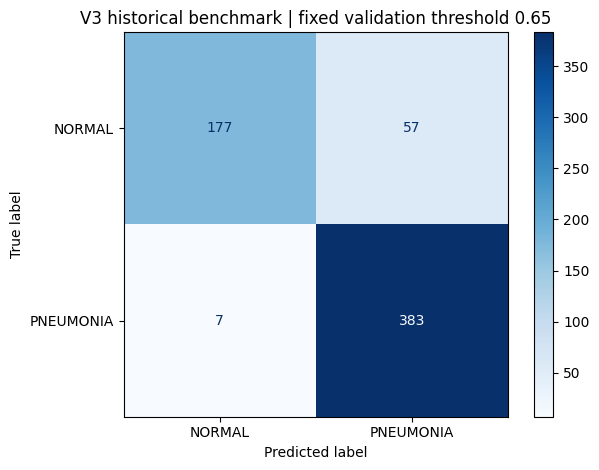

In [ ]:
# One frozen historical-benchmark comparison. No further choice is made from these results.
assert hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest() == json.loads((V3_DIR / 'locked_policy.json').read_text())['model_sha256']
if (V3_DIR / 'historical_test_predictions.csv').exists():
    v3_test_frame = pd.read_csv(V3_DIR / 'historical_test_predictions.csv')
    print('Reusing the stored historical-test predictions; no second inference pass.')
else:
    v3_historical_ds = v3_ordered_dataset(test_file_paths).prefetch(tf.data.AUTOTUNE)
    v3_historical_prob = v3_predict(v3_restored_model, v3_historical_ds)
    v3_test_frame = pd.DataFrame({'file': v3_manifest['files']['historical_test'],
        'y_true': [class_names.index(Path(p).parent.name) for p in test_file_paths],
        'p_pneumonia': v3_historical_prob})
    v3_test_frame['y_pred'] = (v3_test_frame['p_pneumonia'] >= V3_THRESHOLD).astype(int)
    v3_test_frame.to_csv(V3_DIR / 'historical_test_predictions.csv', index=False)
v3_test_y = v3_test_frame['y_true'].to_numpy()
v3_test_prob = v3_test_frame['p_pneumonia'].to_numpy()
v3_test_pred = (v3_test_prob >= V3_THRESHOLD).astype(int)
v3_test_result = v3_metrics(v3_test_y, v3_test_prob, V3_THRESHOLD)
v3_test_result.update(roc_auc=float(roc_auc_score(v3_test_y, v3_test_prob)), n=len(v3_test_y),
    name='V3_selected', members=V3_MEMBERS, selected_candidate=v3_selected['name'],
    independent_unseen_test=False, benchmark='previously_inspected_official_test')
(V3_DIR / 'historical_test_metrics.json').write_text(json.dumps(v3_test_result, indent=2))

# These baseline counts are the verified saved notebook results, not re-tuned models.
v1_counts = {'name': 'Original_test_selected_0.85', 'threshold': 0.85, 'tn': 201, 'fp': 33, 'fn': 18, 'tp': 372}
v2_counts = {'name': 'Corrected_MobileNetV2_validation_0.30', 'threshold': 0.30, 'tn': 156, 'fp': 78, 'fn': 4, 'tp': 386}
def metrics_from_counts(row):
    tn, fp, fn, tp = [row[k] for k in ('tn', 'fp', 'fn', 'tp')]
    return dict(row, accuracy=(tn + tp)/(tn+fp+fn+tp), precision=tp/(tp+fp), recall=tp/(tp+fn),
        specificity=tn/(tn+fp), f1=2*tp/(2*tp+fp+fn))
v3_benchmarks = [metrics_from_counts(v1_counts), metrics_from_counts(v2_counts), v3_test_result]
v3_benchmark_frame = pd.DataFrame(v3_benchmarks)
v3_benchmark_frame.to_csv(V3_DIR / 'historical_benchmark_comparison.csv', index=False)
v3_original = v3_benchmarks[0]
v3_vs_original = {k: {'original': v3_original[k], 'v3': v3_test_result[k],
    'v3_strictly_higher': bool(v3_test_result[k] > v3_original[k])} for k in ['accuracy', 'precision', 'recall', 'f1', 'specificity']}
(V3_DIR / 'comparison_to_original.json').write_text(json.dumps(v3_vs_original, indent=2))
print('HISTORICAL BENCHMARK COMPARISON')
print(v3_benchmark_frame[['name', 'threshold', 'accuracy', 'precision', 'recall', 'specificity', 'f1', 'tn', 'fp', 'fn', 'tp']].to_string(index=False))
print('Selected candidate:', v3_selected['name'])
print('Historical test ROC-AUC:', v3_test_result['roc_auc'])
print('All four classification metrics strictly exceed original:', all(v3_vs_original[k]['v3_strictly_higher'] for k in ['accuracy', 'precision', 'recall', 'f1']))
print('This is a descriptive historical comparison; model development was motivated by earlier benchmark results.')
v3_report = classification_report(v3_test_y, v3_test_pred, labels=[0, 1], target_names=class_names, digits=4, zero_division=0)
(V3_DIR / 'classification_report.txt').write_text(v3_report)
print(v3_report)
v3_cm = confusion_matrix(v3_test_y, v3_test_pred, labels=[0, 1])
ConfusionMatrixDisplay(v3_cm, display_labels=class_names).plot(cmap='Blues')
plt.title(f'V3 historical benchmark | fixed validation threshold {V3_THRESHOLD:.2f}')
plt.tight_layout()
plt.savefig(V3_DIR / 'historical_test_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()


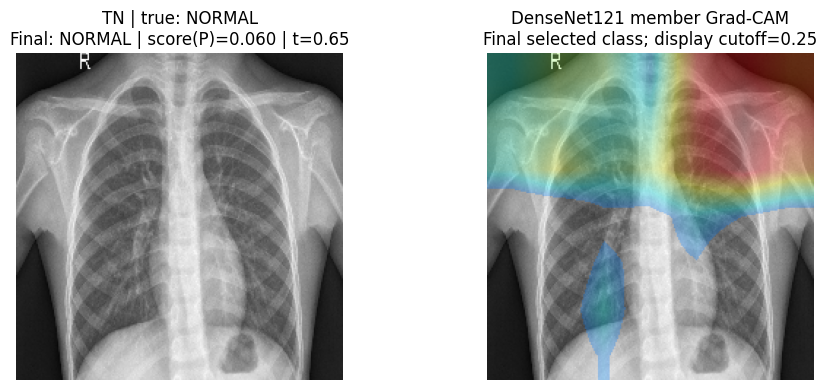

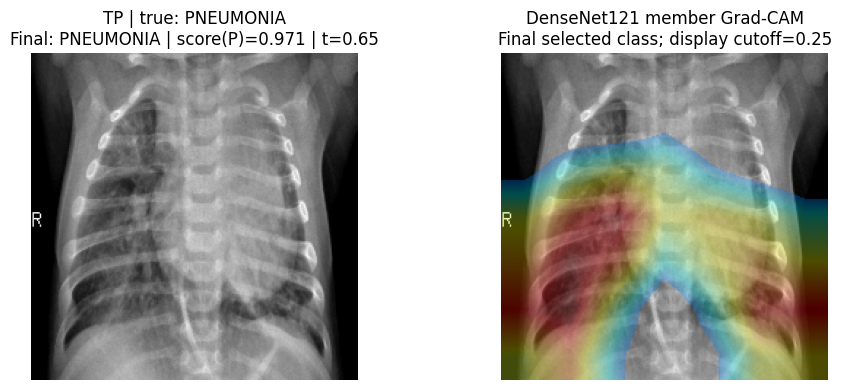

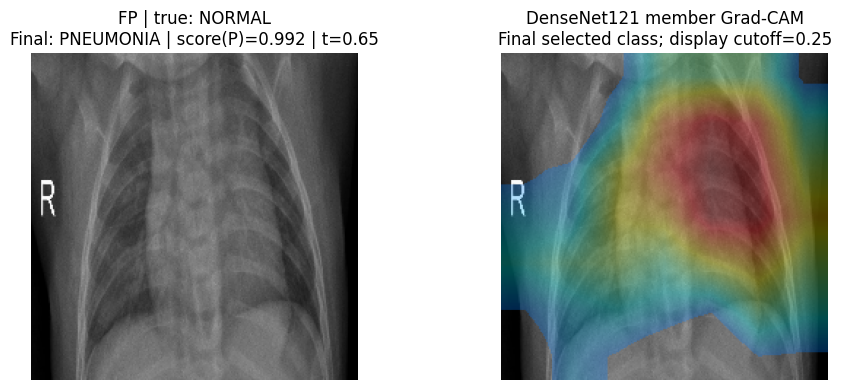

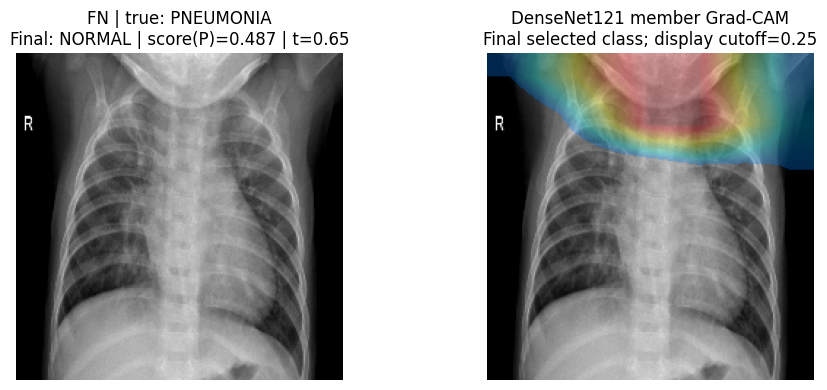

First-in-file-order examples were used; no selection for attractive heatmaps.


In [ ]:
# Member Grad-CAM for the class selected by the final model/ensemble.
# For an ensemble, this displays each member separately and is not a full explanation of the mean model.
def v3_image(path):
    image = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
    return tf.image.resize(image, (224, 224), method='bilinear')[None, ...]

def v3_member_gradcam(member, image, explain_pneumonia):
    grad_model = tf.keras.Model(member.inputs, [member.get_layer('last_conv_features').output, member.outputs[0]])
    with tf.GradientTape() as tape:
        features, score = grad_model(image, training=False)
        target = score[:, 0] if explain_pneumonia else 1.0 - score[:, 0]
    gradient = tape.gradient(target, features)
    if gradient is None:
        raise RuntimeError('Member Grad-CAM graph is disconnected.')
    weights = tf.reduce_mean(tf.cast(gradient, tf.float32), axis=(0, 1, 2))
    heatmap = tf.reduce_sum(tf.cast(features[0], tf.float32) * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    return (heatmap / (tf.reduce_max(heatmap) + 1e-8)).numpy()

def v3_show_case(path, category, heatmap_cutoff=0.25, alpha=0.30):
    image = v3_image(path)
    score = float(np.asarray(v3_restored_model(image, training=False)).ravel()[0])
    decision = int(score >= V3_THRESHOLD)
    original = np.clip(image.numpy()[0], 0, 255).astype(np.uint8)
    fig, axes = plt.subplots(1, len(V3_MEMBERS) + 1, figsize=(5*(len(V3_MEMBERS)+1), 4))
    axes = np.atleast_1d(axes)
    axes[0].imshow(original)
    axes[0].set_title(f'{category} | true: {Path(path).parent.name}\nFinal: {class_names[decision]} | score(P)={score:.3f} | t={V3_THRESHOLD:.2f}')
    for ax, name in zip(axes[1:], V3_MEMBERS):
        heatmap = cv2.resize(v3_member_gradcam(v3_member_models[name], image, bool(decision)), (224, 224))
        mask = heatmap >= heatmap_cutoff
        colors = cv2.cvtColor(cv2.applyColorMap(np.uint8(255*heatmap), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
        blended = np.clip((1-alpha)*original.astype(float) + alpha*colors.astype(float), 0, 255)
        ax.imshow(np.where(mask[..., None], blended, original).astype(np.uint8))
        ax.set_title(f'{name} member Grad-CAM\nFinal selected class; display cutoff={heatmap_cutoff:.2f}')
    for ax in axes:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(V3_DIR / f'{category}_{Path(path).stem}_member_gradcam.png', dpi=140, bbox_inches='tight')
    plt.show()

v3_case_groups = {
    'TN': np.flatnonzero((v3_test_y == 0) & (v3_test_pred == 0)),
    'TP': np.flatnonzero((v3_test_y == 1) & (v3_test_pred == 1)),
    'FP': np.flatnonzero((v3_test_y == 0) & (v3_test_pred == 1)),
    'FN': np.flatnonzero((v3_test_y == 1) & (v3_test_pred == 0))}
v3_examples = []
for category, indices in v3_case_groups.items():
    if not len(indices):
        print(category, 'has no example at the locked threshold.')
        continue
    index = int(indices[0])
    path = test_file_paths[index]
    v3_examples.append({'category': category, 'file': str(Path(path).relative_to(base_dir))})
    v3_show_case(path, category)
(V3_DIR / 'gradcam_examples.json').write_text(json.dumps(v3_examples, indent=2))
print('First-in-file-order examples were used; no selection for attractive heatmaps.')


In [ ]:
# Integrity checks, reproducible export and a precise result summary.
import zipfile
import platform
import sklearn

v3_manifest['historical_test_hashes'] = {str(Path(p).relative_to(base_dir)): v3_test_digests[str(p)] for p in test_file_paths}
v3_manifest['filename_proxy_keys'] = {s: [filename_group(p) for p in paths] for s, paths in
    [('train', v3_fit_paths), ('validation', v3_dev_paths), ('historical_test', test_file_paths)]}
v3_manifest['identity_audit'] = {
    'source_train_test_shared_proxy_keys_before_exclusion': len({filename_group(p) for p in all_source_train} & v3_test_groups),
    'source_train_test_shared_byte_hashes_before_exclusion': len(set(train_digest_map.values()) & v3_test_hashes),
    'final_train_validation_shared_proxy_keys': len(set(v3_manifest['filename_proxy_keys']['train']) & set(v3_manifest['filename_proxy_keys']['validation'])),
    'final_pool_test_shared_proxy_keys': len((set(v3_manifest['filename_proxy_keys']['train']) | set(v3_manifest['filename_proxy_keys']['validation'])) & v3_test_groups),
    'final_pool_test_shared_byte_hashes': len(set(v3_manifest['hashes'].values()) & v3_test_hashes)
}
assert v3_manifest['identity_audit']['final_train_validation_shared_proxy_keys'] == 0
assert v3_manifest['identity_audit']['final_pool_test_shared_proxy_keys'] == 0
assert v3_manifest['identity_audit']['final_pool_test_shared_byte_hashes'] == 0
(V3_DIR / 'split_manifest.json').write_text(json.dumps(v3_manifest, indent=2))
assert np.array_equal(v3_test_pred, (v3_test_prob >= V3_THRESHOLD).astype(int))
assert v3_cm.tolist() == [[v3_test_result['tn'], v3_test_result['fp']], [v3_test_result['fn'], v3_test_result['tp']]]
assert hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest() == v3_locked_policy['model_sha256']
v3_environment = {'python': platform.python_version(), 'tensorflow': tf.__version__,
    'keras': tf.keras.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
    'sklearn': sklearn.__version__, 'mixed_precision': tf.keras.mixed_precision.global_policy().name,
    'selected_model_sha256': v3_locked_policy['model_sha256'],
    'members': V3_MEMBERS, 'decision_threshold': V3_THRESHOLD, 'dataset_root': str(base_dir)}
(V3_DIR / 'environment.json').write_text(json.dumps(v3_environment, indent=2))
v3_all_better = all(v3_vs_original[k]['v3_strictly_higher'] for k in ['accuracy', 'precision', 'recall', 'f1'])
v3_summary = f'''# Pneumonia V3 - Grouped Validation Development

Selected model: {v3_selected['name']}
Decision threshold: {V3_THRESHOLD:.2f}, locked on grouped internal validation.
Training/validation/historical-test sizes: {len(v3_fit_paths)} / {len(v3_dev_paths)} / {len(test_file_paths)}.
Validation precision: {v3_selected['precision']:.6f}
Validation recall: {v3_selected['recall']:.6f}
Validation specificity: {v3_selected['specificity']:.6f}

Historical-test accuracy: {v3_test_result['accuracy']:.6f}
Historical-test precision: {v3_test_result['precision']:.6f}
Historical-test recall: {v3_test_result['recall']:.6f}
Historical-test F1: {v3_test_result['f1']:.6f}
Historical-test ROC-AUC: {v3_test_result['roc_auc']:.6f}
Confusion matrix [[TN, FP], [FN, TP]]: {v3_cm.tolist()}
All four metrics strictly exceed saved original: {v3_all_better}

Three candidate networks and two predeclared equal-mean ensembles were compared on validation only.
No threshold/model adjustment was made after the V3 historical-test score.
The earlier image-level split had {v3_audit['byte_identical_hashes_shared_train_validation']} exact-byte hashes and {v3_audit['filename_proxy_groups_shared_train_validation']} filename-proxy groups shared across training and validation.
V3 separates proxy groups and exact bytes; clinical patient identity and near-duplicates remain unverified.
The official test has already been inspected and informed the improvement request. These are descriptive historical-benchmark results, not independent unseen-test evidence or a clinical-performance claim.
Grad-CAM examples explain individual members for the final selected class. Ensemble member maps do not constitute a full explanation of the mean model.

Load selected_model.keras with tf.keras.models.load_model(path, compile=False).
Input: RGB float32 image resized bilinearly to 224 x 224, pixels 0..255. Model-specific normalization is embedded.
Output: uncalibrated PNEUMONIA score; classify as PNEUMONIA when score >= locked_policy.json decision_threshold.
'''
(V3_DIR / 'RUN_SUMMARY.md').write_text(v3_summary)

chart_metrics = ['accuracy', 'precision', 'recall', 'f1']
chart_labels = ['Accuracy', 'Pneumonia precision', 'Pneumonia recall', 'Pneumonia F1']
positions = np.arange(len(chart_metrics))
fig, ax = plt.subplots(figsize=(12, 5.5))
for offset, (row, label, color) in enumerate(zip(v3_benchmarks,
        ['Original (test-selected threshold)', 'Corrected MobileNetV2', 'V3 (validation-selected)'],
        ['#8c98a7', '#e7a654', '#167d8d'])):
    values = [100 * row[key] for key in chart_metrics]
    bars = ax.bar(positions + (offset-1)*0.25, values, width=0.25, label=label, color=color)
    ax.bar_label(bars, labels=[f'{v:.2f}' for v in values], padding=3, fontsize=8)
ax.set_xticks(positions, chart_labels)
ax.set_ylim(0, 110)
ax.set_ylabel('Percent')
ax.set_title('Same historical benchmark: three saved project versions\nDifferent training and selection protocols; descriptive comparison')
ax.legend(loc='lower left', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(V3_DIR / 'three_version_comparison.png', dpi=170, bbox_inches='tight')
plt.close(fig)

# Keep the self-contained selected inference model plus all development evidence.
# Training checkpoints and redundant individual candidate models remain in runtime, outside the deliverable archive.
v3_archive_path = Path(str(V3_DIR) + '_DELIVERY.zip')
with zipfile.ZipFile(v3_archive_path, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as archive:
    for path in sorted(V3_DIR.iterdir()):
        if path.is_file() and not path.name.endswith('.weights.h5') and (path.suffix != '.keras' or path.name == 'selected_model.keras'):
            archive.write(path, path.name)
print(v3_summary)
print('V3 DELIVERY ARCHIVE:', v3_archive_path)
print('Saved selected model:', V3_MODEL_PATH)
print('Selected model hash:', v3_locked_policy['model_sha256'])
print('Validation-only selection, threshold/prediction consistency and export checks passed.')


# Pneumonia V3 - Grouped Validation Development

Selected model: DenseNet121
Decision threshold: 0.65, locked on grouped internal validation.
Training/validation/historical-test sizes: 4056 / 681 / 624.
Validation precision: 1.000000
Validation recall: 0.955734
Validation specificity: 1.000000

Historical-test accuracy: 0.897436
Historical-test precision: 0.870455
Historical-test recall: 0.982051
Historical-test F1: 0.922892
Historical-test ROC-AUC: 0.967006
Confusion matrix [[TN, FP], [FN, TP]]: [[177, 57], [7, 383]]
All four metrics strictly exceed saved original: False

Three candidate networks and two predeclared equal-mean ensembles were compared on validation only.
No threshold/model adjustment was made after the V3 historical-test score.
The earlier image-level split had 7 exact-byte hashes and 409 filename-proxy groups shared across training and validation.
V3 separates proxy groups and exact bytes; clinical patient identity and near-duplicates remain unverified.
The official t

In [ ]:
# Focused second development stage: a harder filename-source holdout for NORMAL.
# This stage follows the V3 historical result and is explicitly benchmark-informed development.
from copy import deepcopy

V3_COMPLETED_DIR = V3_DIR
V3_COMPLETED_RESULT = deepcopy(v3_test_result) if 'v3_test_result' in globals() else None
V3_COMPLETED_POLICY = deepcopy(v3_locked_policy) if 'v3_locked_policy' in globals() else None
V4_DIR = Path('/content/pneumonia_v4') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
V4_DIR.mkdir(parents=True, exist_ok=False)
def normal_filename_source(path):
    return 'NORMAL2' if Path(path).name.startswith('NORMAL2-') else 'IM'

v4_source_counts = {s: dict(Counter(normal_filename_source(p) for p in paths if Path(p).parent.name == 'NORMAL'))
    for s, paths in [('v3_train', v3_fit_paths), ('v3_validation', v3_dev_paths), ('historical_test', test_file_paths)]}
print('NORMAL filename-prefix counts:', json.dumps(v4_source_counts, indent=2))

# Quarantine every IM NORMAL proxy component for validation.
# PNEUMONIA validation components stay the same as the grouped V3 split.
# The normalized candidate is trained afresh from ImageNet, so these IM images never enter its fitting.
v4_dev_groups = {root_group(filename_group(p)) for p in v3_pool
    if Path(p).parent.name == 'NORMAL' and normal_filename_source(p) == 'IM'}
v4_dev_groups |= {root_group(filename_group(p)) for p in v3_dev_paths if Path(p).parent.name == 'PNEUMONIA'}
v4_fit_paths = [str(p) for p in v3_pool if root_group(filename_group(p)) not in v4_dev_groups]
v4_dev_paths = [str(p) for p in v3_pool if root_group(filename_group(p)) in v4_dev_groups]
assert all(normal_filename_source(p) == 'NORMAL2' for p in v4_fit_paths if Path(p).parent.name == 'NORMAL')
assert not (set(v4_fit_paths) & set(v4_dev_paths))
assert not ({root_group(filename_group(p)) for p in v4_fit_paths} & {root_group(filename_group(p)) for p in v4_dev_paths})

V4_CONFIG = deepcopy(V3_CONFIG)
V4_CONFIG.update(stage='V4_domain_proxy_holdout', candidate_models=['DenseNet121_Normalized'], fixed_ensembles=[],
    head_epochs=5, fine_tune_epochs=10,
    normalization='Per-image channel centering; L2 normalization across HWC; rescale to mean 128 and approx std 50; clip to [0,255]. No fitted dataset statistics.',
    validation_split_rule='All source-training IM NORMAL proxy components plus the pre-existing grouped validation PNEUMONIA components. Remaining components fit the model.',
    provenance='Designed after the V3 historical-benchmark comparison. This is adaptive development, not a fresh independent confirmatory evaluation.',
    stop_rule='One normalized DenseNet candidate from fresh ImageNet weights; select its checkpoint and threshold on domain-proxy validation; one further descriptive historical comparison.')
(V4_DIR / 'development_protocol.json').write_text(json.dumps(V4_CONFIG, indent=2))
(V4_DIR / 'normal_filename_source_counts.json').write_text(json.dumps(v4_source_counts, indent=2))
(V4_DIR / 'prior_split_audit.json').write_text(json.dumps(v3_audit, indent=2))
if V3_COMPLETED_RESULT:
    (V4_DIR / 'previous_v3_metrics.json').write_text(json.dumps(V3_COMPLETED_RESULT, indent=2))

# Reuse the tested training/export machinery with a NEW output directory, split and fresh model builder.
V3_DIR = V4_DIR
V3_CONFIG = V4_CONFIG
v3_fit_paths, v3_dev_paths = v4_fit_paths, v4_dev_paths
v3_fit_ordered = v3_ordered_dataset(v3_fit_paths).unbatch().cache()
v3_dev_ds = v3_ordered_dataset(v3_dev_paths).cache().prefetch(tf.data.AUTOTUNE)
v3_dev_y = np.array([class_names.index(Path(p).parent.name) for p in v3_dev_paths])
v4_counts = Counter(class_names.index(Path(p).parent.name) for p in v3_fit_paths)
v3_weights = {c: len(v3_fit_paths)/(2*count) for c, count in v4_counts.items()}
v3_weights[0] *= V4_CONFIG['normal_weight_multiplier']
v3_grid = np.array(V4_CONFIG['threshold_grid'])
v3_records = {}
v3_manifest = {'protocol': V4_CONFIG, 'class_names': class_names, 'removed': v3_removed,
    'files': {s: [str(Path(p).relative_to(base_dir)) for p in paths] for s, paths in
        [('train', v3_fit_paths), ('validation', v3_dev_paths), ('historical_test', test_file_paths)]},
    'group_keys': {s: [root_group(filename_group(p)) for p in paths] for s, paths in
        [('train', v3_fit_paths), ('validation', v3_dev_paths)]},
    'hashes': {str(Path(p).relative_to(base_dir)): train_digest_map[str(p)] for p in v3_pool}}
(V4_DIR / 'split_manifest.json').write_text(json.dumps(v3_manifest, indent=2))
print('V4 directory:', V4_DIR)
print('V4 train/validation sizes:', len(v3_fit_paths), len(v3_dev_paths))
print('V4 validation classes:', dict(Counter(v3_dev_y)))
print('Filename prefixes are domain proxies, not verified scanner/site labels.')
print('No current V4 historical-test predictions exist.')


NORMAL filename-prefix counts: {
  "v3_train": {
    "IM": 517,
    "NORMAL2": 639
  },
  "v3_validation": {
    "IM": 80,
    "NORMAL2": 104
  },
  "historical_test": {
    "IM": 69,
    "NORMAL2": 165
  }
}
V4 directory: /content/pneumonia_v4/20261022T075359_047844Z
V4 train/validation sizes: 3643 1094
V4 validation classes: {np.int64(0): 597, np.int64(1): 497}
Filename prefixes are domain proxies, not verified scanner/site labels.
No current V4 historical-test predictions exist.


In [ ]:
# Fully serializable per-image photometric standardization; fresh ImageNet initialization.
def v4_build_normalized(name):
    assert name == 'DenseNet121_Normalized'
    inputs = layers.Input((224, 224, 3), dtype='float32', name='image')
    augmentation = tf.keras.Sequential([
        layers.RandomRotation(0.03, fill_mode='reflect', seed=42),
        layers.RandomTranslation(0.04, 0.04, fill_mode='reflect', seed=43),
        layers.RandomZoom(0.08, fill_mode='reflect', seed=44)
    ], name='geometric_augmentation')
    x = augmentation(inputs)
    means = layers.GlobalAveragePooling2D(keepdims=True, dtype='float32', name='per_image_means')(x)
    x = layers.Subtract(dtype='float32', name='center_each_image')([x, means])
    x = layers.UnitNormalization(axis=(1, 2, 3), dtype='float32', name='per_image_l2')(x)
    x = layers.Rescaling(scale=50.0*np.sqrt(224*224*3), offset=128.0,
        dtype='float32', name='standardize_image_contrast')(x)
    x = layers.ReLU(max_value=255.0, dtype='float32', name='clip_pixels')(x)
    x = tf.keras.applications.densenet.preprocess_input(x)
    backbone = tf.keras.applications.DenseNet121(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.Activation('linear', name='last_conv_features')(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(V4_CONFIG['dropout'], seed=47)(x)
    output = layers.Dense(1, activation='sigmoid', dtype='float32', name='prediction')(x)
    return tf.keras.Model(inputs, output, name='v4_DenseNet121_Normalized'), backbone, 140

v3_build = v4_build_normalized
print('V4 normalized DenseNet builder ready. No prior fitted model weights are reused.')


V4 normalized DenseNet builder ready. No prior fitted model weights are reused.


In [ ]:
v4_result = v3_train_candidate('DenseNet121_Normalized')



TRAINING DenseNet121_Normalized HEAD
Epoch 1/5
 | DenseNet121_Normalized validation checkpoint: spec=0.9447, precision=0.9311, recall=0.8974, feasible=False
152/152 - 65s - 425ms/step - accuracy: 0.6810 - auc: 0.7969 - loss: 0.6183 - val_accuracy: 0.9196 - val_auc: 0.9772 - val_loss: 0.2845 - learning_rate: 0.0010
Epoch 2/5
 | DenseNet121_Normalized validation checkpoint: spec=0.9598, precision=0.9508, recall=0.9336, feasible=False
152/152 - 44s - 292ms/step - accuracy: 0.8348 - auc: 0.9338 - loss: 0.3952 - val_accuracy: 0.9369 - val_auc: 0.9864 - val_loss: 0.2344 - learning_rate: 0.0010
Epoch 3/5
 | DenseNet121_Normalized validation checkpoint: spec=0.9531, precision=0.9442, recall=0.9537, feasible=False
152/152 - 43s - 286ms/step - accuracy: 0.8699 - auc: 0.9515 - loss: 0.3455 - val_accuracy: 0.9461 - val_auc: 0.9878 - val_loss: 0.2025 - learning_rate: 0.0010
Epoch 4/5
 | DenseNet121_Normalized validation checkpoint: spec=0.9531, precision=0.9446, recall=0.9598, feasible=False
152/1

In [ ]:
# Descriptive diagnosis of the already-scored V3 historical benchmark, not V4 model selection.
v4_prior_diagnosis = {}
v4_prior_csv = V3_COMPLETED_DIR / 'historical_test_predictions.csv'
if v4_prior_csv.exists():
    previous = pd.read_csv(v4_prior_csv)
    previous_normal = previous.loc[previous['y_true'] == 0].copy()
    previous_normal['filename_source'] = previous_normal['file'].map(normal_filename_source)
    for source, frame in previous_normal.groupby('filename_source'):
        v4_prior_diagnosis[source] = {'normal_images': len(frame),
            'false_positive': int(frame['y_pred'].sum()),
            'specificity': float(1-frame['y_pred'].mean()),
            'mean_pneumonia_score': float(frame['p_pneumonia'].mean())}
    (V4_DIR / 'previous_v3_normal_error_diagnosis.json').write_text(json.dumps(v4_prior_diagnosis, indent=2))
print('PREVIOUS V3 historical NORMAL diagnosis:', json.dumps(v4_prior_diagnosis, indent=2))
print('This information is historical development feedback, not independent validation.')


PREVIOUS V3 historical NORMAL diagnosis: {
  "IM": {
    "normal_images": 69,
    "false_positive": 7,
    "specificity": 0.8985507246376812,
    "mean_pneumonia_score": 0.188529478867971
  },
  "NORMAL2": {
    "normal_images": 165,
    "false_positive": 50,
    "specificity": 0.696969696969697,
    "mean_pneumonia_score": 0.3816657108787879
  }
}
This information is historical development feedback, not independent validation.


In [2]:
from pathlib import Path
import json
print('Runtime artifact inventory')
for directory in ['/content/pneumonia_v4', '/content/pneumonia_v3', '/content/pneumonia_runs', '/kaggle/input/chest-xray-pneumonia/chest_xray']:
    root = Path(directory)
    print(directory, 'exists=', root.exists())
    if root.exists():
        print([(p.name, p.stat().st_size if p.is_file() else 'directory') for p in sorted(root.iterdir())][:15])


Runtime artifact inventory
/content/pneumonia_v4 exists= False
/content/pneumonia_v3 exists= False
/content/pneumonia_runs exists= False
/kaggle/input/chest-xray-pneumonia/chest_xray exists= False


In [3]:
# V4 reproducible recovery after Colab discarded the previous temporary runtime.
# Prior training outputs are preserved above; this fresh run does not reuse lost weights.
import os
import json
import hashlib
import platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
SEED = 42
tf.keras.utils.set_random_seed(SEED)
RUN_DIR = Path('/content/pneumonia_recovery_audit') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
class_names = ['NORMAL', 'PNEUMONIA']
print('GPU:', tf.config.list_physical_devices('GPU'))

# Public dataset access; credentials are not stored in this notebook.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('kagglehub') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
import kagglehub
print('KaggleHub is ready.')

from pathlib import Path

DATASET_HANDLE = 'paultimothymooney/chest-xray-pneumonia'
# Reuse the download cache. Existing data and credentials are never deleted.
dataset_root = Path(kagglehub.dataset_download(DATASET_HANDLE))
candidate_dirs = sorted(
    [p for p in [dataset_root, *dataset_root.rglob('chest_xray')]
     if (p / 'train' / 'NORMAL').is_dir()
     and (p / 'train' / 'PNEUMONIA').is_dir()
     and (p / 'test' / 'NORMAL').is_dir()
     and (p / 'test' / 'PNEUMONIA').is_dir()],
    key=lambda p: (len(p.parts), str(p))
)
if not candidate_dirs:
    raise FileNotFoundError('No valid train/test dataset root was found.')
base_dir = candidate_dirs[0]
train_dir, val_dir, test_dir = [base_dir / s for s in ('train', 'val', 'test')]
print('Dataset cache:', dataset_root)
print('Selected dataset root:', base_dir)
print('The supplied val directory is not used; validation is split from train.')

# Reconstruct the earlier seeded split only to audit its duplicates and derive file lists.
prior_train_raw, prior_val_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.15, subset='both', seed=42, shuffle=True,
    image_size=(224,224), batch_size=24, label_mode='binary', class_names=class_names)
prior_test_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir, shuffle=False, image_size=(224,224), batch_size=24,
    label_mode='binary', class_names=class_names)
train_paths, val_paths = list(prior_train_raw.file_paths), list(prior_val_raw.file_paths)
test_file_paths = np.array(prior_test_raw.file_paths)

# V3 development audit. No new test predictions are computed here.
import re
import hashlib
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

def filename_group(path):
    name = Path(path).name
    person = re.match(r'person(\d+)_', name, flags=re.I)
    if person:
        return 'pneumonia_person_' + person.group(1)
    normal = re.match(r'(NORMAL2-)?IM-(\d+)-', name, flags=re.I)
    if normal:
        return ('normal2_' if normal.group(1) else 'normal1_') + normal.group(2)
    return 'unparsed_' + Path(path).stem

prior_train_groups = {filename_group(p) for p in train_paths}
prior_val_groups = {filename_group(p) for p in val_paths}
all_source_train = sorted(set(train_paths) | set(val_paths))
def file_digest(path):
    return str(path), hashlib.sha256(Path(path).read_bytes()).hexdigest()
with ThreadPoolExecutor(max_workers=8) as pool:
    train_digest_map = dict(pool.map(file_digest, all_source_train))
prior_train_hashes = {train_digest_map[str(p)] for p in train_paths}
prior_val_hashes = {train_digest_map[str(p)] for p in val_paths}
v3_audit = {
    'prior_train_images': len(train_paths), 'prior_validation_images': len(val_paths),
    'filename_proxy_groups_shared_train_validation': len(prior_train_groups & prior_val_groups),
    'byte_identical_hashes_shared_train_validation': len(prior_train_hashes & prior_val_hashes),
    'unique_source_training_images': len(all_source_train),
    'unique_source_training_hashes': len(set(train_digest_map.values())),
    'filename_proxy_group_count': len({filename_group(p) for p in all_source_train}),
    'unparsed_names': [Path(p).name for p in all_source_train if filename_group(p).startswith('unparsed_')],
    'scope': 'Filename keys are grouping proxies; they do not verify clinical patient identity.'
}
(RUN_DIR / 'v3_development_audit.json').write_text(json.dumps(v3_audit, indent=2))
print(json.dumps(v3_audit, indent=2))


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
KaggleHub is ready.
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset cache: /kaggle/input/chest-xray-pneumonia
Selected dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray
The supplied val directory is not used; validation is split from train.
Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Using 782 files for validation.
Found 624 files belonging to 2 classes.
{
  "prior_train_images": 4434,
  "prior_validation_images": 782,
  "filename_proxy_groups_shared_train_validation": 409,
  "byte_identical_hashes_shared_train_validation": 7,
  "unique_source_training_images": 5216,
  "unique_source_training_hashes": 5190,
  "filename_proxy_group_count": 2846,
  "unparsed_names": [],
  "scope": "Filename keys are grouping proxies; they do not verify clinical patient identity."
}


In [4]:
# V3: fixed development protocol, written before training candidates or scoring the historical test.
from sklearn.model_selection import StratifiedGroupKFold
import time
import gc

V3_DIR = Path('/content/pneumonia_v3') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
V3_DIR.mkdir(parents=True, exist_ok=False)
V3_CONFIG = {
    'seed': 42, 'image_size': [224, 224], 'batch_size': 24,
    'head_epochs': 6, 'fine_tune_epochs': 12,
    'head_lr': 0.001, 'fine_tune_lr': 0.00002,
    'label_smoothing': 0.02, 'dropout': 0.35, 'normal_weight_multiplier': 1.25,
    'precision_floor': 0.95, 'recall_floor': 0.95,
    'threshold_grid': np.round(np.arange(1, 100) / 100, 2).tolist(),
    'selection_rule': 'require validation precision and recall >= 0.95; maximize specificity, then F1, then higher threshold; model ties use ROC-AUC then model name',
    'candidate_models': ['MobileNetV2', 'DenseNet121', 'EfficientNetB0'],
    'fixed_ensembles': [['DenseNet121', 'EfficientNetB0'], ['MobileNetV2', 'DenseNet121', 'EfficientNetB0']],
    'validation_split_rule': 'StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42), first fold only',
    'grouping': 'Connected components of filename person/study proxies and SHA-256 duplicates',
    'test_status': 'Historical benchmark already inspected; current development request is informed by its earlier results. No claim of independent unseen testing.',
    'stop_rule': 'Train the three predeclared candidates, compare the two fixed means on validation, lock one candidate and threshold, score historical test once; do not retune from that score.'
}
(V3_DIR / 'development_protocol.json').write_text(json.dumps(V3_CONFIG, indent=2))
(V3_DIR / 'prior_split_audit.json').write_text(json.dumps(v3_audit, indent=2))

# Test files are checked for identity/group separation only, without model predictions.
with ThreadPoolExecutor(max_workers=8) as pool:
    v3_test_digests = dict(pool.map(file_digest, test_file_paths))
v3_test_hashes = set(v3_test_digests.values())
v3_test_groups = {filename_group(p) for p in test_file_paths}

# Merge proxy groups connected by byte-identical source-training images.
parent = {filename_group(p): filename_group(p) for p in all_source_train}
def root_group(group):
    while parent[group] != group:
        parent[group] = parent[parent[group]]
        group = parent[group]
    return group
def union_groups(a, b):
    a, b = root_group(a), root_group(b)
    if a != b:
        parent[max(a, b)] = min(a, b)
hash_first = {}
for p in all_source_train:
    digest = train_digest_map[p]
    if digest in hash_first:
        assert Path(p).parent.name == Path(hash_first[digest]).parent.name, 'Conflicting labels on an exact duplicate.'
        union_groups(filename_group(p), filename_group(hash_first[digest]))
    else:
        hash_first[digest] = p
excluded_components = {root_group(filename_group(p)) for p in all_source_train
    if filename_group(p) in v3_test_groups or train_digest_map[p] in v3_test_hashes}
v3_pool = []
v3_removed = []
seen_hashes = set()
for p in all_source_train:
    digest = train_digest_map[p]
    if root_group(filename_group(p)) in excluded_components:
        v3_removed.append({'file': str(Path(p).relative_to(base_dir)), 'reason': 'historical_test_identity_or_proxy_group'})
    elif digest in seen_hashes:
        v3_removed.append({'file': str(Path(p).relative_to(base_dir)), 'reason': 'duplicate_within_source_training'})
    else:
        seen_hashes.add(digest)
        v3_pool.append(p)
v3_pool = np.array(v3_pool)
v3_labels = np.array([class_names.index(Path(p).parent.name) for p in v3_pool])
v3_groups = np.array([root_group(filename_group(p)) for p in v3_pool])
v3_fit_idx, v3_dev_idx = next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42).split(v3_pool, v3_labels, v3_groups))
v3_fit_paths = v3_pool[v3_fit_idx].tolist()
v3_dev_paths = v3_pool[v3_dev_idx].tolist()
assert not (set(v3_groups[v3_fit_idx]) & set(v3_groups[v3_dev_idx]))
assert not ({train_digest_map[p] for p in v3_fit_paths} & {train_digest_map[p] for p in v3_dev_paths})
assert not ({train_digest_map[p] for p in v3_fit_paths + v3_dev_paths} & v3_test_hashes)
v3_manifest = {'protocol': V3_CONFIG, 'class_names': class_names, 'removed': v3_removed,
    'files': {s: [str(Path(p).relative_to(base_dir)) for p in paths] for s, paths in
        [('train', v3_fit_paths), ('validation', v3_dev_paths), ('historical_test', test_file_paths)]},
    'group_keys': {s: [root_group(filename_group(p)) for p in paths] for s, paths in
        [('train', v3_fit_paths), ('validation', v3_dev_paths)]},
    'hashes': {str(Path(p).relative_to(base_dir)): train_digest_map[str(p)] for p in v3_pool}}
(V3_DIR / 'split_manifest.json').write_text(json.dumps(v3_manifest, indent=2))
print('V3 run directory:', V3_DIR)
print('V3 train/validation/historical-test:', len(v3_fit_paths), len(v3_dev_paths), len(test_file_paths))
print('V3 removed source images:', Counter(r['reason'] for r in v3_removed))
print('V3 training counts:', Counter(v3_labels[v3_fit_idx]))
print('V3 validation counts:', Counter(v3_labels[v3_dev_idx]))
print('Group-proxy and exact-byte separation checks passed. Near-duplicates and clinical patient identity remain unverified.')

V3_BATCH = V3_CONFIG['batch_size']
def v3_ordered_dataset(paths):
    labels = np.array([class_names.index(Path(p).parent.name) for p in paths], dtype=np.float32)
    def decode(path, label):
        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        return tf.image.resize(image, (224, 224), method='bilinear'), tf.reshape(label, (1,))
    return tf.data.Dataset.from_tensor_slices((list(paths), labels)).map(decode,
        num_parallel_calls=tf.data.AUTOTUNE, deterministic=True).batch(V3_BATCH)

v3_fit_ordered = v3_ordered_dataset(v3_fit_paths).unbatch().cache()
v3_dev_ds = v3_ordered_dataset(v3_dev_paths).cache().prefetch(tf.data.AUTOTUNE)
v3_dev_y = np.array([class_names.index(Path(p).parent.name) for p in v3_dev_paths])
v3_counts = Counter(v3_labels[v3_fit_idx])
v3_weights = {c: len(v3_fit_paths) / (2 * count) for c, count in v3_counts.items()}
v3_weights[0] *= V3_CONFIG['normal_weight_multiplier']
v3_grid = np.array(V3_CONFIG['threshold_grid'])
v3_records = {}
print('Fixed V3 class weights:', v3_weights)
print('No candidate test predictions have been computed.')

# Focused second development stage: a harder filename-source holdout for NORMAL.
# This stage follows the V3 historical result and is explicitly benchmark-informed development.
from copy import deepcopy

V3_COMPLETED_DIR = V3_DIR
V3_COMPLETED_RESULT = deepcopy(v3_test_result) if 'v3_test_result' in globals() else None
V3_COMPLETED_POLICY = deepcopy(v3_locked_policy) if 'v3_locked_policy' in globals() else None
V4_DIR = Path('/content/pneumonia_v4') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
V4_DIR.mkdir(parents=True, exist_ok=False)
def normal_filename_source(path):
    return 'NORMAL2' if Path(path).name.startswith('NORMAL2-') else 'IM'

v4_source_counts = {s: dict(Counter(normal_filename_source(p) for p in paths if Path(p).parent.name == 'NORMAL'))
    for s, paths in [('v3_train', v3_fit_paths), ('v3_validation', v3_dev_paths), ('historical_test', test_file_paths)]}
print('NORMAL filename-prefix counts:', json.dumps(v4_source_counts, indent=2))

# Quarantine every IM NORMAL proxy component for validation.
# PNEUMONIA validation components stay the same as the grouped V3 split.
# The normalized candidate is trained afresh from ImageNet, so these IM images never enter its fitting.
v4_dev_groups = {root_group(filename_group(p)) for p in v3_pool
    if Path(p).parent.name == 'NORMAL' and normal_filename_source(p) == 'IM'}
v4_dev_groups |= {root_group(filename_group(p)) for p in v3_dev_paths if Path(p).parent.name == 'PNEUMONIA'}
v4_fit_paths = [str(p) for p in v3_pool if root_group(filename_group(p)) not in v4_dev_groups]
v4_dev_paths = [str(p) for p in v3_pool if root_group(filename_group(p)) in v4_dev_groups]
assert all(normal_filename_source(p) == 'NORMAL2' for p in v4_fit_paths if Path(p).parent.name == 'NORMAL')
assert not (set(v4_fit_paths) & set(v4_dev_paths))
assert not ({root_group(filename_group(p)) for p in v4_fit_paths} & {root_group(filename_group(p)) for p in v4_dev_paths})

V4_CONFIG = deepcopy(V3_CONFIG)
V4_CONFIG.update(stage='V4_domain_proxy_holdout', candidate_models=['DenseNet121_Normalized'], fixed_ensembles=[],
    head_epochs=5, fine_tune_epochs=10,
    normalization='Per-image channel centering; L2 normalization across HWC; rescale to mean 128 and approx std 50; clip to [0,255]. No fitted dataset statistics.',
    validation_split_rule='All source-training IM NORMAL proxy components plus the pre-existing grouped validation PNEUMONIA components. Remaining components fit the model.',
    provenance='Designed after the V3 historical-benchmark comparison. This is adaptive development, not a fresh independent confirmatory evaluation.',
    stop_rule='One normalized DenseNet candidate from fresh ImageNet weights; select its checkpoint and threshold on domain-proxy validation; one further descriptive historical comparison.')
(V4_DIR / 'development_protocol.json').write_text(json.dumps(V4_CONFIG, indent=2))
(V4_DIR / 'normal_filename_source_counts.json').write_text(json.dumps(v4_source_counts, indent=2))
(V4_DIR / 'prior_split_audit.json').write_text(json.dumps(v3_audit, indent=2))
if V3_COMPLETED_RESULT:
    (V4_DIR / 'previous_v3_metrics.json').write_text(json.dumps(V3_COMPLETED_RESULT, indent=2))

# Reuse the tested training/export machinery with a NEW output directory, split and fresh model builder.
V3_DIR = V4_DIR
V3_CONFIG = V4_CONFIG
v3_fit_paths, v3_dev_paths = v4_fit_paths, v4_dev_paths
v3_fit_ordered = v3_ordered_dataset(v3_fit_paths).unbatch().cache()
v3_dev_ds = v3_ordered_dataset(v3_dev_paths).cache().prefetch(tf.data.AUTOTUNE)
v3_dev_y = np.array([class_names.index(Path(p).parent.name) for p in v3_dev_paths])
v4_counts = Counter(class_names.index(Path(p).parent.name) for p in v3_fit_paths)
v3_weights = {c: len(v3_fit_paths)/(2*count) for c, count in v4_counts.items()}
v3_weights[0] *= V4_CONFIG['normal_weight_multiplier']
v3_grid = np.array(V4_CONFIG['threshold_grid'])
v3_records = {}
v3_manifest = {'protocol': V4_CONFIG, 'class_names': class_names, 'removed': v3_removed,
    'files': {s: [str(Path(p).relative_to(base_dir)) for p in paths] for s, paths in
        [('train', v3_fit_paths), ('validation', v3_dev_paths), ('historical_test', test_file_paths)]},
    'group_keys': {s: [root_group(filename_group(p)) for p in paths] for s, paths in
        [('train', v3_fit_paths), ('validation', v3_dev_paths)]},
    'hashes': {str(Path(p).relative_to(base_dir)): train_digest_map[str(p)] for p in v3_pool}}
(V4_DIR / 'split_manifest.json').write_text(json.dumps(v3_manifest, indent=2))
print('V4 directory:', V4_DIR)
print('V4 train/validation sizes:', len(v3_fit_paths), len(v3_dev_paths))
print('V4 validation classes:', dict(Counter(v3_dev_y)))
print('Filename prefixes are domain proxies, not verified scanner/site labels.')
print('No current V4 historical-test predictions exist.')


V3 run directory: /content/pneumonia_v3/20261022T122505_891435Z
V3 train/validation/historical-test: 4056 681 624
V3 removed source images: Counter({'historical_test_identity_or_proxy_group': 457, 'duplicate_within_source_training': 22})
V3 training counts: Counter({np.int64(1): 2900, np.int64(0): 1156})
V3 validation counts: Counter({np.int64(1): 497, np.int64(0): 184})
Group-proxy and exact-byte separation checks passed. Near-duplicates and clinical patient identity remain unverified.
Fixed V3 class weights: {np.int64(0): 2.192906574394464, np.int64(1): 0.6993103448275862}
No candidate test predictions have been computed.
NORMAL filename-prefix counts: {
  "v3_train": {
    "IM": 517,
    "NORMAL2": 639
  },
  "v3_validation": {
    "IM": 80,
    "NORMAL2": 104
  },
  "historical_test": {
    "IM": 69,
    "NORMAL2": 165
  }
}
V4 directory: /content/pneumonia_v4/20261022T122508_285919Z
V4 train/validation sizes: 3643 1094
V4 validation classes: {np.int64(0): 597, np.int64(1): 497}
Fi

In [5]:
# Model construction and validation-only checkpoint selection.
from tensorflow.keras import layers
tf.keras.mixed_precision.set_global_policy('mixed_float16')

def v3_metrics(truth, probabilities, threshold):
    prediction = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
    return {'threshold': float(threshold), 'accuracy': float((tn + tp) / len(truth)),
        'precision': float(tp / (tp + fp)) if tp + fp else 0.0,
        'recall': float(tp / (tp + fn)), 'specificity': float(tn / (tn + fp)),
        'f1': float(2 * tp / (2 * tp + fp + fn)) if 2 * tp + fp + fn else 0.0,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}

def v3_policy_for(probabilities):
    rows = [v3_metrics(v3_dev_y, probabilities, t) for t in v3_grid]
    feasible = [r for r in rows if r['precision'] >= V3_CONFIG['precision_floor'] and r['recall'] >= V3_CONFIG['recall_floor']]
    if feasible:
        best = sorted(feasible, key=lambda r: (-r['specificity'], -r['f1'], -r['threshold']))[0]
        best['constraints_met'] = True
    else:
        # This only ranks checkpoints for diagnostic retention; final selection still stops if no candidate is feasible.
        best = sorted(rows, key=lambda r: (-r['f1'], -r['specificity'], -r['threshold']))[0]
        best['constraints_met'] = False
    best['roc_auc'] = float(roc_auc_score(v3_dev_y, probabilities))
    return best

def v3_predict(model, dataset):
    return np.concatenate([np.asarray(model(images, training=False)).ravel() for images, _ in dataset])

class V3DevCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, name):
        super().__init__()
        self.name = name
        self.best_key = None
        self.best_metrics = None
        self.rows = []
        self.phase = 'head'
        self.path = V3_DIR / f'{name}_best.weights.h5'
    def on_epoch_end(self, epoch, logs=None):
        probabilities = v3_predict(self.model, v3_dev_ds)
        result = v3_policy_for(probabilities)
        key = (int(result['constraints_met']), result['specificity'] if result['constraints_met'] else result['f1'], result['f1'], result['roc_auc'])
        result.update(model=self.name, phase=self.phase, epoch=int(epoch + 1))
        self.rows.append(dict(result))
        if self.best_key is None or key > self.best_key:
            self.best_key, self.best_metrics = key, dict(result)
            self.model.save_weights(self.path)
            np.save(V3_DIR / f'{self.name}_validation_probabilities.npy', probabilities)
        print(f" | {self.name} validation checkpoint: spec={result['specificity']:.4f}, precision={result['precision']:.4f}, recall={result['recall']:.4f}, feasible={result['constraints_met']}")
        pd.DataFrame(self.rows).to_csv(V3_DIR / f'{self.name}_epoch_selection.csv', index=False)

def v3_build(name):
    inputs = layers.Input((224, 224, 3), name=f'{name}_image')
    augmentation = tf.keras.Sequential([
        layers.RandomRotation(0.03, fill_mode='reflect', seed=42),
        layers.RandomTranslation(0.04, 0.04, fill_mode='reflect', seed=43),
        layers.RandomZoom(0.08, fill_mode='reflect', seed=44),
        layers.RandomBrightness(0.15, value_range=(0, 255), seed=45),
        layers.RandomContrast(0.15, seed=46)
    ], name=f'{name}_augmentation')
    x = augmentation(inputs)
    if name == 'MobileNetV2':
        backbone = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(224, 224, 3), name='v3_mobilenetv2')
        x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
        unfreeze = 60
    elif name == 'DenseNet121':
        backbone = tf.keras.applications.DenseNet121(include_top=False, weights='imagenet', input_shape=(224, 224, 3), name='v3_densenet121')
        x = tf.keras.applications.densenet.preprocess_input(x)
        unfreeze = 140
    elif name == 'EfficientNetB0':
        # Keep the standard backbone name: this Keras version derives its pretrained-weight filename from it.
        backbone = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
        # EfficientNet embeds its own pixel rescaling. Input remains 0..255.
        unfreeze = 80
    else:
        raise ValueError(name)
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.Activation('linear', name='last_conv_features')(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(V3_CONFIG['dropout'], seed=47)(x)
    outputs = layers.Dense(1, activation='sigmoid', dtype='float32', name='prediction')(x)
    return tf.keras.Model(inputs, outputs, name=f'v3_{name}'), backbone, unfreeze

def v3_compile(candidate, lr):
    candidate.compile(optimizer=tf.keras.optimizers.Adam(lr),
        loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=V3_CONFIG['label_smoothing']),
        metrics=[tf.keras.metrics.AUC(name='auc'), tf.keras.metrics.BinaryAccuracy(name='accuracy')])

def v3_train_candidate(name):
    assert name in V3_CONFIG['candidate_models']
    started = time.time()
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(42)
    candidate, backbone, unfreeze = v3_build(name)
    train_data = v3_fit_ordered.shuffle(min(2000, len(v3_fit_paths)), seed=42,
        reshuffle_each_iteration=True).batch(V3_BATCH).apply(tf.data.experimental.assert_cardinality(
        (len(v3_fit_paths) + V3_BATCH - 1) // V3_BATCH)).prefetch(tf.data.AUTOTUNE)
    checkpoint = V3DevCheckpoint(name)
    def callbacks():
        return [checkpoint, tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=False),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7)]
    v3_compile(candidate, V3_CONFIG['head_lr'])
    print('\nTRAINING', name, 'HEAD')
    candidate.fit(train_data, validation_data=v3_dev_ds, epochs=V3_CONFIG['head_epochs'],
        class_weight=v3_weights, callbacks=callbacks(), verbose=2)
    candidate.load_weights(checkpoint.path)
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = False
    for layer in backbone.layers[-unfreeze:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True
    checkpoint.phase = 'fine_tune'
    v3_compile(candidate, V3_CONFIG['fine_tune_lr'])
    print('\nTRAINING', name, 'FINE-TUNE; BatchNormalization remains frozen')
    candidate.fit(train_data, validation_data=v3_dev_ds, epochs=V3_CONFIG['fine_tune_epochs'],
        class_weight=v3_weights, callbacks=callbacks(), verbose=2)
    candidate.load_weights(checkpoint.path)
    probabilities = v3_predict(candidate, v3_dev_ds)
    result = v3_policy_for(probabilities)
    # Export an inference model without optimizer state.
    inference = tf.keras.Model(candidate.inputs, candidate.outputs, name=candidate.name)
    path = V3_DIR / f'{name}.keras'
    inference.save(path)
    restored = tf.keras.models.load_model(path, compile=False)
    restored_probabilities = v3_predict(restored, v3_dev_ds)
    np.testing.assert_allclose(probabilities, restored_probabilities, atol=1e-5, rtol=1e-4)
    pd.DataFrame({'file': v3_manifest['files']['validation'], 'y_true': v3_dev_y,
        'p_pneumonia': restored_probabilities}).to_csv(V3_DIR / f'{name}_validation_predictions.csv', index=False)
    result.update(name=name, members=[name], model_file=str(path), elapsed_seconds=time.time() - started,
        selected_checkpoint=checkpoint.best_metrics, reload_max_abs_error=float(np.max(np.abs(probabilities - restored_probabilities))))
    v3_records[name] = result
    (V3_DIR / 'candidate_records.json').write_text(json.dumps(v3_records, indent=2))
    print('CANDIDATE COMPLETE', json.dumps(result, indent=2))
    del candidate, inference, restored, backbone, train_data
    gc.collect()
    return result

print('Three candidate definitions are ready. All checkpoint decisions use grouped validation only.')

# Fully serializable per-image photometric standardization; fresh ImageNet initialization.
def v4_build_normalized(name):
    assert name == 'DenseNet121_Normalized'
    inputs = layers.Input((224, 224, 3), dtype='float32', name='image')
    augmentation = tf.keras.Sequential([
        layers.RandomRotation(0.03, fill_mode='reflect', seed=42),
        layers.RandomTranslation(0.04, 0.04, fill_mode='reflect', seed=43),
        layers.RandomZoom(0.08, fill_mode='reflect', seed=44)
    ], name='geometric_augmentation')
    x = augmentation(inputs)
    means = layers.GlobalAveragePooling2D(keepdims=True, dtype='float32', name='per_image_means')(x)
    x = layers.Subtract(dtype='float32', name='center_each_image')([x, means])
    x = layers.UnitNormalization(axis=(1, 2, 3), dtype='float32', name='per_image_l2')(x)
    x = layers.Rescaling(scale=50.0*np.sqrt(224*224*3), offset=128.0,
        dtype='float32', name='standardize_image_contrast')(x)
    x = layers.ReLU(max_value=255.0, dtype='float32', name='clip_pixels')(x)
    x = tf.keras.applications.densenet.preprocess_input(x)
    backbone = tf.keras.applications.DenseNet121(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.Activation('linear', name='last_conv_features')(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(V4_CONFIG['dropout'], seed=47)(x)
    output = layers.Dense(1, activation='sigmoid', dtype='float32', name='prediction')(x)
    return tf.keras.Model(inputs, output, name='v4_DenseNet121_Normalized'), backbone, 140

v3_build = v4_build_normalized
print('V4 normalized DenseNet builder ready. No prior fitted model weights are reused.')


Three candidate definitions are ready. All checkpoint decisions use grouped validation only.
V4 normalized DenseNet builder ready. No prior fitted model weights are reused.


In [6]:
v4_result = v3_train_candidate('DenseNet121_Normalized')


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

TRAINING DenseNet121_Normalized HEAD
Epoch 1/5
 | DenseNet121_Normalized validation checkpoint: spec=0.9447, precision=0.9311, recall=0.8974, feasible=False
152/152 - 71s - 469ms/step - accuracy: 0.6810 - auc: 0.7969 - loss: 0.6183 - val_accuracy: 0.9196 - val_auc: 0.9772 - val_loss: 0.2845 - learning_rate: 0.0010
Epoch 2/5
 | DenseNet121_Normalized validation checkpoint: spec=0.9598, precision=0.9508, recall=0.9336, feasible=False
152/152 - 45s - 299ms/step - accuracy: 0.8348 - auc: 0.9338 - loss: 0.3952 - val_accuracy: 0.9369 - val_auc: 0.9864 - val_loss: 0.2344 - learning_rate: 0.0010
Epoch 3/5
 | DenseNet121_Normalized validation checkpoint: spec=0.9531, precision=0.9442, recall=0.9537, feasible=False
152/152 - 47s - 311ms/step - accuracy: 0.8699 - auc: 0.9515 - loss: 0.3455 - val_accuracy: 0.9461 - val_auc: 0.9878 - val_loss: 0.2025 - learning_rate: 0.0010
Epoch 4/5
 | DenseNet121_Normalized validation checkpoint: spec=0.9531, pr

In [7]:
# V4 validation-only deployment policy, fixed before the V4 historical pass.
v3_calibration_addendum = {
    'stage': 'after V4 training-validation development, before V4 historical-test inference',
    'deployment_threshold_rule': 'validation precision >= 0.95 and recall >= 0.95; maximize specificity, then higher threshold, then F1',
    'checkpoint_rule': V3_CONFIG['selection_rule'],
    'uses_current_v4_historical_test_results': False,
    'adaptive_development_after_v3_benchmark': True,
    'not_claimed_as_fully_preregistered': True
}
(V3_DIR / 'calibration_addendum.json').write_text(json.dumps(v3_calibration_addendum, indent=2))
def v3_deployment_policy_for(probabilities):
    rows = [v3_metrics(v3_dev_y, probabilities, t) for t in v3_grid]
    feasible = [r for r in rows if r['precision'] >= V3_CONFIG['precision_floor'] and r['recall'] >= V3_CONFIG['recall_floor']]
    best = (sorted(feasible, key=lambda r: (-r['specificity'], -r['threshold'], -r['f1']))[0]
        if feasible else sorted(rows, key=lambda r: (-r['f1'], -r['specificity'], -r['threshold']))[0])
    best.update(constraints_met=bool(feasible), roc_auc=float(roc_auc_score(v3_dev_y, probabilities)))
    return best

v3_probability_bank = {}
for name in V3_CONFIG['candidate_models']:
    frame = pd.read_csv(V3_DIR / f'{name}_validation_predictions.csv')
    assert frame['file'].tolist() == v3_manifest['files']['validation']
    assert np.array_equal(frame['y_true'].to_numpy(), v3_dev_y)
    v3_probability_bank[name] = frame['p_pneumonia'].to_numpy()
    v3_records[name]['checkpoint_operating_point'] = {k: v3_records[name][k] for k in ['threshold', 'precision', 'recall', 'specificity', 'f1']}
    v3_records[name].update(v3_deployment_policy_for(v3_probability_bank[name]))
for members in V3_CONFIG['fixed_ensembles']:
    name = 'Mean_' + '_'.join(members)
    probabilities = np.mean([v3_probability_bank[m] for m in members], axis=0)
    v3_probability_bank[name] = probabilities
    result = v3_deployment_policy_for(probabilities)
    result.update(name=name, members=members, model_file=None)
    v3_records[name] = result
    pd.DataFrame({'file': v3_manifest['files']['validation'], 'y_true': v3_dev_y,
        'p_pneumonia': probabilities}).to_csv(V3_DIR / f'{name}_validation_predictions.csv', index=False)
v3_comparison = pd.DataFrame(v3_records.values())
v3_comparison.drop(columns=['selected_checkpoint'], errors='ignore').to_csv(V3_DIR / 'validation_model_comparison.csv', index=False)
(V3_DIR / 'candidate_records.json').write_text(json.dumps(v3_records, indent=2))
print('GROUPED VALIDATION COMPARISON ONLY')
print(v3_comparison[['name', 'threshold', 'precision', 'recall', 'specificity', 'f1', 'roc_auc', 'constraints_met']].to_string(index=False))
feasible_models = [r for r in v3_records.values() if r['constraints_met']]
if not feasible_models:
    raise RuntimeError('No predeclared candidate meets both validation floors. No historical-test evaluation is authorized by this protocol.')
v3_selected = sorted(feasible_models, key=lambda r: (-r['specificity'], -r['f1'], -r['roc_auc'], r['name']))[0]
V3_THRESHOLD = float(v3_selected['threshold'])
V3_MEMBERS = v3_selected['members']
tf.keras.backend.clear_session()
gc.collect()
v3_member_models = {name: tf.keras.models.load_model(V3_DIR / f'{name}.keras', compile=False) for name in V3_MEMBERS}
if len(V3_MEMBERS) == 1:
    v3_selected_model = v3_member_models[V3_MEMBERS[0]]
else:
    v3_inputs = tf.keras.layers.Input((224, 224, 3), name='ensemble_image')
    v3_outputs = tf.keras.layers.Average(dtype='float32', name='mean_pneumonia_score')([
        v3_member_models[name](v3_inputs, training=False) for name in V3_MEMBERS])
    v3_selected_model = tf.keras.Model(v3_inputs, v3_outputs, name='v3_selected_mean_ensemble')
V3_MODEL_PATH = V3_DIR / 'selected_model.keras'
v3_selected_model.save(V3_MODEL_PATH)
v3_restored_model = tf.keras.models.load_model(V3_MODEL_PATH, compile=False)
v3_reload_probabilities = v3_predict(v3_restored_model, v3_dev_ds)
np.testing.assert_allclose(v3_reload_probabilities, v3_probability_bank[v3_selected['name']], rtol=1e-4, atol=1e-5)
v3_model_hash = hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest()
v3_locked_policy = {
    'status': 'locked_before_V4_historical_test_pass', 'selected_candidate': v3_selected['name'],
    'members': V3_MEMBERS, 'decision_threshold': V3_THRESHOLD,
    'comparison': 'P(PNEUMONIA) >= decision_threshold',
    'class_names': class_names, 'selection_dataset': 'IM_NORMAL_domain_proxy_grouped_validation',
    'validation_metrics': v3_selected, 'protocol': V3_CONFIG, 'calibration_addendum': v3_calibration_addendum,
    'model_sha256': v3_model_hash,
    'validation_reload_max_abs_error': float(np.max(np.abs(v3_reload_probabilities - v3_probability_bank[v3_selected['name']]))),
    'historical_test_previously_inspected': True,
    'independent_unseen_test': False
}
(V3_DIR / 'locked_policy.json').write_text(json.dumps(v3_locked_policy, indent=2))
print('LOCKED CANDIDATE:', v3_selected['name'])
print('LOCKED THRESHOLD:', V3_THRESHOLD)
print('Model reload and validation prediction parity verified before historical test.')


GROUPED VALIDATION COMPARISON ONLY
                  name  threshold  precision  recall  specificity       f1  roc_auc  constraints_met
DenseNet121_Normalized       0.64    0.99789 0.95171     0.998325 0.974253 0.998062             True
LOCKED CANDIDATE: DenseNet121_Normalized
LOCKED THRESHOLD: 0.64
Model reload and validation prediction parity verified before historical test.


HISTORICAL BENCHMARK COMPARISON
                                 name  threshold  accuracy  precision   recall  specificity       f1  tn  fp  fn  tp
          Original_test_selected_0.85       0.85  0.918269   0.918519 0.953846     0.858974 0.935849 201  33  18 372
Corrected_MobileNetV2_validation_0.30       0.30  0.868590   0.831897 0.989744     0.666667 0.903981 156  78   4 386
               V3_Grouped_DenseNet121       0.65  0.897436   0.870455 0.982051     0.756410 0.922892 177  57   7 383
            V4_Normalized_DenseNet121       0.64  0.892628   0.869565 0.974359     0.756410 0.918984 177  57  10 380
Selected candidate: DenseNet121_Normalized
Historical test ROC-AUC: 0.9632588209511288
All four classification metrics strictly exceed original: False
This is a descriptive historical comparison; model development was motivated by earlier benchmark results.
              precision    recall  f1-score   support

      NORMAL     0.9465    0.7564    0.8409       234
   PNEUMONIA    

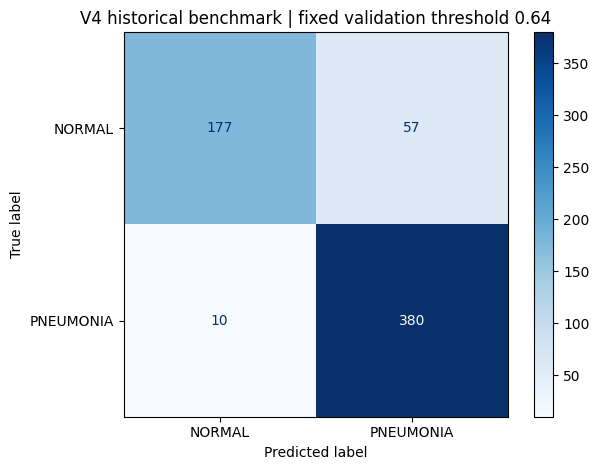

V4 historical pass complete. No threshold or model adjustment follows this score.


In [8]:
# One frozen historical-benchmark comparison. No further choice is made from these results.
assert hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest() == json.loads((V3_DIR / 'locked_policy.json').read_text())['model_sha256']
if (V3_DIR / 'historical_test_predictions.csv').exists():
    v3_test_frame = pd.read_csv(V3_DIR / 'historical_test_predictions.csv')
    print('Reusing the stored historical-test predictions; no second inference pass.')
else:
    v3_historical_ds = v3_ordered_dataset(test_file_paths).prefetch(tf.data.AUTOTUNE)
    v3_historical_prob = v3_predict(v3_restored_model, v3_historical_ds)
    v3_test_frame = pd.DataFrame({'file': v3_manifest['files']['historical_test'],
        'y_true': [class_names.index(Path(p).parent.name) for p in test_file_paths],
        'p_pneumonia': v3_historical_prob})
    v3_test_frame['y_pred'] = (v3_test_frame['p_pneumonia'] >= V3_THRESHOLD).astype(int)
    v3_test_frame.to_csv(V3_DIR / 'historical_test_predictions.csv', index=False)
v3_test_y = v3_test_frame['y_true'].to_numpy()
v3_test_prob = v3_test_frame['p_pneumonia'].to_numpy()
v3_test_pred = (v3_test_prob >= V3_THRESHOLD).astype(int)
v3_test_result = v3_metrics(v3_test_y, v3_test_prob, V3_THRESHOLD)
v3_test_result.update(roc_auc=float(roc_auc_score(v3_test_y, v3_test_prob)), n=len(v3_test_y),
    name='V4_Normalized_DenseNet121', members=V3_MEMBERS, selected_candidate=v3_selected['name'],
    independent_unseen_test=False, benchmark='previously_inspected_official_test')
(V3_DIR / 'historical_test_metrics.json').write_text(json.dumps(v3_test_result, indent=2))

# These baseline counts are the verified saved notebook results, not re-tuned models.
v1_counts = {'name': 'Original_test_selected_0.85', 'threshold': 0.85, 'tn': 201, 'fp': 33, 'fn': 18, 'tp': 372}
v2_counts = {'name': 'Corrected_MobileNetV2_validation_0.30', 'threshold': 0.30, 'tn': 156, 'fp': 78, 'fn': 4, 'tp': 386}
def metrics_from_counts(row):
    tn, fp, fn, tp = [row[k] for k in ('tn', 'fp', 'fn', 'tp')]
    return dict(row, accuracy=(tn + tp)/(tn+fp+fn+tp), precision=tp/(tp+fp), recall=tp/(tp+fn),
        specificity=tn/(tn+fp), f1=2*tp/(2*tp+fp+fn))
v3_reference = dict(V3_COMPLETED_RESULT) if V3_COMPLETED_RESULT else metrics_from_counts(
    {'name': 'V3_Grouped_DenseNet121', 'threshold': 0.65, 'tn': 177, 'fp': 57, 'fn': 7, 'tp': 383})
v3_reference['name'] = 'V3_Grouped_DenseNet121'
v3_benchmarks = [metrics_from_counts(v1_counts), metrics_from_counts(v2_counts), v3_reference, v3_test_result]
v3_benchmark_frame = pd.DataFrame(v3_benchmarks)
v3_benchmark_frame.to_csv(V3_DIR / 'historical_benchmark_comparison.csv', index=False)
v3_original = v3_benchmarks[0]
v3_vs_original = {k: {'original': v3_original[k], 'v4': v3_test_result[k],
    'v4_strictly_higher': bool(v3_test_result[k] > v3_original[k])} for k in ['accuracy', 'precision', 'recall', 'f1', 'specificity']}
(V3_DIR / 'comparison_to_original.json').write_text(json.dumps(v3_vs_original, indent=2))
print('HISTORICAL BENCHMARK COMPARISON')
print(v3_benchmark_frame[['name', 'threshold', 'accuracy', 'precision', 'recall', 'specificity', 'f1', 'tn', 'fp', 'fn', 'tp']].to_string(index=False))
print('Selected candidate:', v3_selected['name'])
print('Historical test ROC-AUC:', v3_test_result['roc_auc'])
print('All four classification metrics strictly exceed original:', all(v3_vs_original[k]['v4_strictly_higher'] for k in ['accuracy', 'precision', 'recall', 'f1']))
print('This is a descriptive historical comparison; model development was motivated by earlier benchmark results.')
v3_report = classification_report(v3_test_y, v3_test_pred, labels=[0, 1], target_names=class_names, digits=4, zero_division=0)
(V3_DIR / 'classification_report.txt').write_text(v3_report)
print(v3_report)
v3_cm = confusion_matrix(v3_test_y, v3_test_pred, labels=[0, 1])
ConfusionMatrixDisplay(v3_cm, display_labels=class_names).plot(cmap='Blues')
plt.title(f'V4 historical benchmark | fixed validation threshold {V3_THRESHOLD:.2f}')
plt.tight_layout()
plt.savefig(V3_DIR / 'historical_test_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()
print("V4 historical pass complete. No threshold or model adjustment follows this score.")


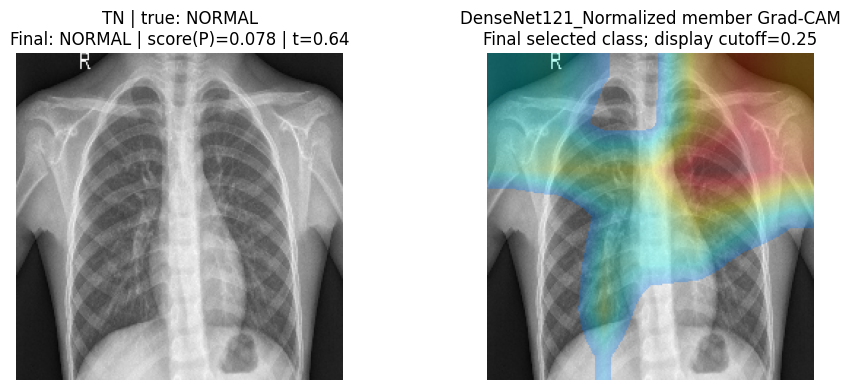

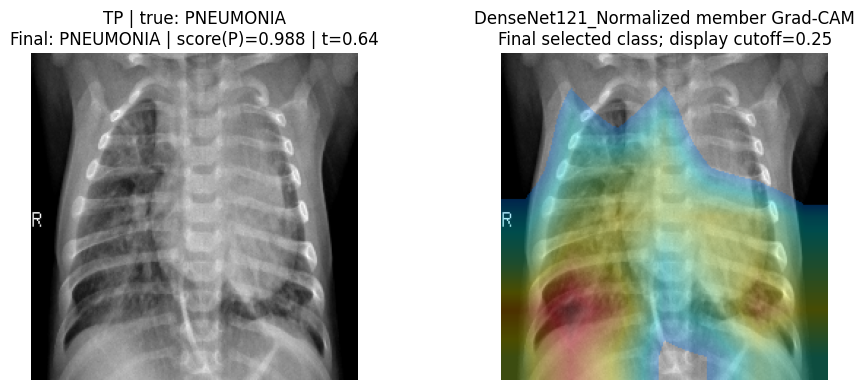

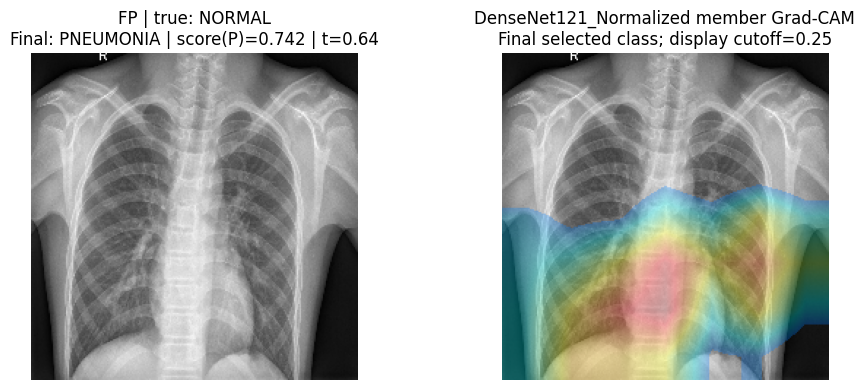

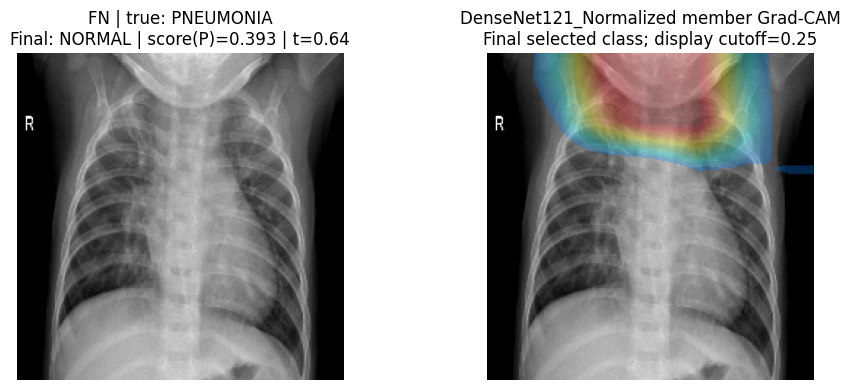

First-in-file-order examples were used; no selection for attractive heatmaps.


In [9]:
# Member Grad-CAM for the class selected by the final model/ensemble.
# For an ensemble, this displays each member separately and is not a full explanation of the mean model.
def v3_image(path):
    image = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
    return tf.image.resize(image, (224, 224), method='bilinear')[None, ...]

def v3_member_gradcam(member, image, explain_pneumonia):
    grad_model = tf.keras.Model(member.inputs, [member.get_layer('last_conv_features').output, member.outputs[0]])
    with tf.GradientTape() as tape:
        features, score = grad_model(image, training=False)
        target = score[:, 0] if explain_pneumonia else 1.0 - score[:, 0]
    gradient = tape.gradient(target, features)
    if gradient is None:
        raise RuntimeError('Member Grad-CAM graph is disconnected.')
    weights = tf.reduce_mean(tf.cast(gradient, tf.float32), axis=(0, 1, 2))
    heatmap = tf.reduce_sum(tf.cast(features[0], tf.float32) * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    return (heatmap / (tf.reduce_max(heatmap) + 1e-8)).numpy()

def v3_show_case(path, category, heatmap_cutoff=0.25, alpha=0.30):
    image = v3_image(path)
    score = float(np.asarray(v3_restored_model(image, training=False)).ravel()[0])
    decision = int(score >= V3_THRESHOLD)
    original = np.clip(image.numpy()[0], 0, 255).astype(np.uint8)
    fig, axes = plt.subplots(1, len(V3_MEMBERS) + 1, figsize=(5*(len(V3_MEMBERS)+1), 4))
    axes = np.atleast_1d(axes)
    axes[0].imshow(original)
    axes[0].set_title(f'{category} | true: {Path(path).parent.name}\nFinal: {class_names[decision]} | score(P)={score:.3f} | t={V3_THRESHOLD:.2f}')
    for ax, name in zip(axes[1:], V3_MEMBERS):
        heatmap = cv2.resize(v3_member_gradcam(v3_member_models[name], image, bool(decision)), (224, 224))
        mask = heatmap >= heatmap_cutoff
        colors = cv2.cvtColor(cv2.applyColorMap(np.uint8(255*heatmap), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
        blended = np.clip((1-alpha)*original.astype(float) + alpha*colors.astype(float), 0, 255)
        ax.imshow(np.where(mask[..., None], blended, original).astype(np.uint8))
        ax.set_title(f'{name} member Grad-CAM\nFinal selected class; display cutoff={heatmap_cutoff:.2f}')
    for ax in axes:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(V3_DIR / f'{category}_{Path(path).stem}_member_gradcam.png', dpi=140, bbox_inches='tight')
    plt.show()

v3_case_groups = {
    'TN': np.flatnonzero((v3_test_y == 0) & (v3_test_pred == 0)),
    'TP': np.flatnonzero((v3_test_y == 1) & (v3_test_pred == 1)),
    'FP': np.flatnonzero((v3_test_y == 0) & (v3_test_pred == 1)),
    'FN': np.flatnonzero((v3_test_y == 1) & (v3_test_pred == 0))}
v3_examples = []
for category, indices in v3_case_groups.items():
    if not len(indices):
        print(category, 'has no example at the locked threshold.')
        continue
    index = int(indices[0])
    path = test_file_paths[index]
    v3_examples.append({'category': category, 'file': str(Path(path).relative_to(base_dir))})
    v3_show_case(path, category)
(V3_DIR / 'gradcam_examples.json').write_text(json.dumps(v3_examples, indent=2))
print('First-in-file-order examples were used; no selection for attractive heatmaps.')


In [10]:
# Integrity checks, reproducible export and a precise result summary.
import zipfile
import platform
import sklearn

v3_manifest['historical_test_hashes'] = {str(Path(p).relative_to(base_dir)): v3_test_digests[str(p)] for p in test_file_paths}
v3_manifest['filename_proxy_keys'] = {s: [filename_group(p) for p in paths] for s, paths in
    [('train', v3_fit_paths), ('validation', v3_dev_paths), ('historical_test', test_file_paths)]}
v3_manifest['identity_audit'] = {
    'source_train_test_shared_proxy_keys_before_exclusion': len({filename_group(p) for p in all_source_train} & v3_test_groups),
    'source_train_test_shared_byte_hashes_before_exclusion': len(set(train_digest_map.values()) & v3_test_hashes),
    'final_train_validation_shared_proxy_keys': len(set(v3_manifest['filename_proxy_keys']['train']) & set(v3_manifest['filename_proxy_keys']['validation'])),
    'final_pool_test_shared_proxy_keys': len((set(v3_manifest['filename_proxy_keys']['train']) | set(v3_manifest['filename_proxy_keys']['validation'])) & v3_test_groups),
    'final_pool_test_shared_byte_hashes': len(set(v3_manifest['hashes'].values()) & v3_test_hashes)
}
assert v3_manifest['identity_audit']['final_train_validation_shared_proxy_keys'] == 0
assert v3_manifest['identity_audit']['final_pool_test_shared_proxy_keys'] == 0
assert v3_manifest['identity_audit']['final_pool_test_shared_byte_hashes'] == 0
(V3_DIR / 'split_manifest.json').write_text(json.dumps(v3_manifest, indent=2))
assert np.array_equal(v3_test_pred, (v3_test_prob >= V3_THRESHOLD).astype(int))
assert v3_cm.tolist() == [[v3_test_result['tn'], v3_test_result['fp']], [v3_test_result['fn'], v3_test_result['tp']]]
assert hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest() == v3_locked_policy['model_sha256']
v3_environment = {'python': platform.python_version(), 'tensorflow': tf.__version__,
    'keras': tf.keras.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
    'sklearn': sklearn.__version__, 'mixed_precision': tf.keras.mixed_precision.global_policy().name,
    'selected_model_sha256': v3_locked_policy['model_sha256'],
    'members': V3_MEMBERS, 'decision_threshold': V3_THRESHOLD, 'dataset_root': str(base_dir)}
(V3_DIR / 'environment.json').write_text(json.dumps(v3_environment, indent=2))
v3_all_better = all(v3_vs_original[k]['v4_strictly_higher'] for k in ['accuracy', 'precision', 'recall', 'f1'])
v3_summary = f'''# Pneumonia V4 - Normalized DenseNet and Domain-Proxy Validation

Selected model: {v3_selected['name']}
Decision threshold: {V3_THRESHOLD:.2f}, locked on grouped internal validation.
Training/validation/historical-test sizes: {len(v3_fit_paths)} / {len(v3_dev_paths)} / {len(test_file_paths)}.
Validation precision: {v3_selected['precision']:.6f}
Validation recall: {v3_selected['recall']:.6f}
Validation specificity: {v3_selected['specificity']:.6f}

Historical-test accuracy: {v3_test_result['accuracy']:.6f}
Historical-test precision: {v3_test_result['precision']:.6f}
Historical-test recall: {v3_test_result['recall']:.6f}
Historical-test F1: {v3_test_result['f1']:.6f}
Historical-test ROC-AUC: {v3_test_result['roc_auc']:.6f}
Confusion matrix [[TN, FP], [FN, TP]]: {v3_cm.tolist()}
All four metrics strictly exceed saved original: {v3_all_better}

V3 compared three networks and two fixed means. It did not surpass the original on every measure.
V4 follows the V3 historical result and is adaptive development. It uses one fresh ImageNet DenseNet121,
per-image contrast normalization embedded in the saved model, and a harder NORMAL filename-source holdout.
V4 checkpoint selection uses validation specificity, F1 and AUC subject to precision/recall >=0.95.
The deployment threshold maximizes validation specificity then higher threshold while retaining both floors.
No threshold/model adjustment is made after the V4 historical-test score.
NORMAL filename prefixes are proxies, not verified clinical sites or scanners.
The earlier image-level split had {v3_audit['byte_identical_hashes_shared_train_validation']} exact-byte hashes and {v3_audit['filename_proxy_groups_shared_train_validation']} filename-proxy groups shared across training and validation.
V3 separates proxy groups and exact bytes; clinical patient identity and near-duplicates remain unverified.
The official test has already been inspected and informed the improvement request. These are descriptive historical-benchmark results, not independent unseen-test evidence or a clinical-performance claim.
Grad-CAM examples explain individual members for the final selected class. Ensemble member maps do not constitute a full explanation of the mean model.

Load selected_model.keras with tf.keras.models.load_model(path, compile=False).
Input: RGB float32 image resized bilinearly to 224 x 224, pixels 0..255. Model-specific normalization is embedded.
Output: uncalibrated PNEUMONIA score; classify as PNEUMONIA when score >= locked_policy.json decision_threshold.
'''
(V3_DIR / 'RUN_SUMMARY.md').write_text(v3_summary)

chart_metrics = ['accuracy', 'precision', 'recall', 'f1']
chart_labels = ['Accuracy', 'Pneumonia precision', 'Pneumonia recall', 'Pneumonia F1']
positions = np.arange(len(chart_metrics))
fig, ax = plt.subplots(figsize=(12, 5.5))
for offset, (row, label, color) in enumerate(zip(v3_benchmarks,
        ['Original (test-selected threshold)', 'Corrected MobileNetV2', 'V3 grouped DenseNet121', 'V4 normalized DenseNet121'],
        ['#8c98a7', '#e7a654', '#6a7faa', '#167d8d'])):
    values = [100 * row[key] for key in chart_metrics]
    bars = ax.bar(positions + (offset-1.5)*0.20, values, width=0.20, label=label, color=color)
    ax.bar_label(bars, labels=[f'{v:.2f}' for v in values], padding=3, fontsize=8)
ax.set_xticks(positions, chart_labels)
ax.set_ylim(0, 110)
ax.set_ylabel('Percent')
ax.set_title('Same historical benchmark: four saved project versions\nDifferent training and selection protocols; descriptive comparison')
ax.legend(loc='lower left', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(V3_DIR / 'four_version_comparison.png', dpi=170, bbox_inches='tight')
plt.close(fig)

# Keep the self-contained selected inference model plus all development evidence.
# Training checkpoints and redundant individual candidate models remain in runtime, outside the deliverable archive.
(V3_DIR / 'historical_normal_source_error_counts.json').write_text(json.dumps({source: {
    'normal_images': len(frame), 'false_positive': int(frame['y_pred'].sum())}
    for source, frame in v3_test_frame.loc[v3_test_frame.y_true == 0].assign(
        source=lambda d: d['file'].map(normal_filename_source)).groupby('source')}, indent=2))

v3_archive_path = Path(str(V3_DIR) + '_DELIVERY.zip')
with zipfile.ZipFile(v3_archive_path, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as archive:
    for path in sorted(V3_DIR.iterdir()):
        if path.is_file() and not path.name.endswith('.weights.h5') and (path.suffix != '.keras' or path.name == 'selected_model.keras'):
            archive.write(path, path.name)
print(v3_summary)
print('V4 DELIVERY ARCHIVE:', v3_archive_path)
print('Saved selected model:', V3_MODEL_PATH)
print('Selected model hash:', v3_locked_policy['model_sha256'])
print('Validation-only selection, threshold/prediction consistency and export checks passed.')


# Pneumonia V4 - Normalized DenseNet and Domain-Proxy Validation

Selected model: DenseNet121_Normalized
Decision threshold: 0.64, locked on grouped internal validation.
Training/validation/historical-test sizes: 3643 / 1094 / 624.
Validation precision: 0.997890
Validation recall: 0.951710
Validation specificity: 0.998325

Historical-test accuracy: 0.892628
Historical-test precision: 0.869565
Historical-test recall: 0.974359
Historical-test F1: 0.918984
Historical-test ROC-AUC: 0.963259
Confusion matrix [[TN, FP], [FN, TP]]: [[177, 57], [10, 380]]
All four metrics strictly exceed saved original: False

V3 compared three networks and two fixed means. It did not surpass the original on every measure.
V4 follows the V3 historical result and is adaptive development. It uses one fresh ImageNet DenseNet121,
per-image contrast normalization embedded in the saved model, and a harder NORMAL filename-source holdout.
V4 checkpoint selection uses validation specificity, F1 and AUC subject to preci

In [11]:
# V5 is a NEW adaptive development experiment after V4, whose frozen results are preserved.
# No V4 weights or V4 threshold are changed. No V5 benchmark scores exist at this stage.
from copy import deepcopy
V4_COMPLETED_DIR = V3_DIR
V4_COMPLETED_RESULT = deepcopy(v3_test_result) if 'v3_test_result' in globals() else None
if 'V3_COMPLETED_RESULT' not in globals():
    V3_COMPLETED_RESULT = None
V5_DIR = Path('/content/pneumonia_v5') / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
V5_DIR.mkdir(parents=True, exist_ok=False)
V5_CONFIG = deepcopy(V3_CONFIG)
V5_CONFIG.update(stage='V5_source_stratified_EfficientNetV2B0_320', seed=42, split_seed=314,
    image_size=[320,320], batch_size=16, candidate_models=['EfficientNetV2B0_320'], fixed_ensembles=[],
    head_epochs=4, fine_tune_epochs=10, head_lr=0.001, fine_tune_lr=0.00001,
    label_smoothing=0.04, dropout=0.40, normal_weight_multiplier=1.0,
    normalization='EfficientNetV2 built-in preprocessing; RGB float32 pixels 0..255; no external rescaling.',
    validation_split_rule='StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=314), first fold; strata NORMAL IM, NORMAL NORMAL2, PNEUMONIA; groups combine filename proxies and exact bytes.',
    provenance='Adaptive development after the V3 and V4 historical results. This is not a new independent test or a controlled attribution study.',
    stop_rule='One fresh EfficientNetV2B0 at 320px, four head epochs and at most ten fine-tuning epochs; select checkpoint and threshold on source-stratified validation only; freeze before one descriptive historical pass.')
(V5_DIR/'development_protocol.json').write_text(json.dumps(V5_CONFIG,indent=2))
(V5_DIR/'prior_split_audit.json').write_text(json.dumps(v3_audit,indent=2))
if V4_COMPLETED_RESULT:
    (V5_DIR/'previous_v4_metrics.json').write_text(json.dumps(V4_COMPLETED_RESULT,indent=2))
v5_strata=np.array([2 if Path(p).parent.name=='PNEUMONIA' else int(Path(p).name.startswith('NORMAL2-')) for p in v3_pool])
v5_groups=np.array([root_group(filename_group(p)) for p in v3_pool])
v5_fit_idx,v5_dev_idx=next(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=314).split(v3_pool,v5_strata,v5_groups))
v3_fit_paths=v3_pool[v5_fit_idx].tolist()
v3_dev_paths=v3_pool[v5_dev_idx].tolist()
assert not (set(v5_groups[v5_fit_idx])&set(v5_groups[v5_dev_idx]))
assert not ({train_digest_map[p] for p in v3_fit_paths}&{train_digest_map[p] for p in v3_dev_paths})
assert not ({train_digest_map[p] for p in v3_fit_paths+v3_dev_paths}&v3_test_hashes)
V3_DIR,V3_CONFIG,V3_BATCH=V5_DIR,V5_CONFIG,V5_CONFIG['batch_size']
def v3_ordered_dataset(paths):
    labels=np.array([class_names.index(Path(p).parent.name) for p in paths],dtype=np.float32)
    def read_image(path,label):
        image=tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False)
        image=tf.image.resize(image,(320,320),method='bilinear')
        image.set_shape((320,320,3))
        return tf.cast(image,tf.float32),tf.reshape(label,(1,))
    return tf.data.Dataset.from_tensor_slices((list(paths),labels)).map(read_image,num_parallel_calls=tf.data.AUTOTUNE).batch(V3_BATCH)
v3_fit_ordered=v3_ordered_dataset(v3_fit_paths).unbatch().cache()
v3_dev_ds=v3_ordered_dataset(v3_dev_paths).cache().prefetch(tf.data.AUTOTUNE)
v3_dev_y=np.array([class_names.index(Path(p).parent.name) for p in v3_dev_paths])
v5_counts=Counter(class_names.index(Path(p).parent.name) for p in v3_fit_paths)
v3_weights={c:len(v3_fit_paths)/(2*count) for c,count in v5_counts.items()}
v3_grid=np.array(V5_CONFIG['threshold_grid'])
v3_records={}
v3_manifest={'protocol':V5_CONFIG,'class_names':class_names,'removed':v3_removed,
    'files':{s:[str(Path(p).relative_to(base_dir)) for p in paths] for s,paths in
        [('train',v3_fit_paths),('validation',v3_dev_paths),('historical_test',test_file_paths)]},
    'group_keys':{s:[root_group(filename_group(p)) for p in paths] for s,paths in [('train',v3_fit_paths),('validation',v3_dev_paths)]},
    'hashes':{str(Path(p).relative_to(base_dir)):train_digest_map[str(p)] for p in v3_pool}}
(V5_DIR/'split_manifest.json').write_text(json.dumps(v3_manifest,indent=2))
v5_source_counts={s:dict(Counter('PNEUMONIA' if Path(p).parent.name=='PNEUMONIA' else ('NORMAL2' if Path(p).name.startswith('NORMAL2-') else 'IM') for p in paths))
    for s,paths in [('train',v3_fit_paths),('validation',v3_dev_paths)]}
assert all(v5_source_counts['validation'].get(s,0)>0 for s in ['IM','NORMAL2','PNEUMONIA'])
(V5_DIR/'source_strata_counts.json').write_text(json.dumps(v5_source_counts,indent=2))
print('V5 directory:',V5_DIR)
print('V5 sizes:',len(v3_fit_paths),len(v3_dev_paths),len(test_file_paths))
print('V5 source-proxy strata:',json.dumps(v5_source_counts,indent=2))
print('V5 protocol saved before training and before V5 historical inference.')


V5 directory: /content/pneumonia_v5/20261022T124651_224595Z
V5 sizes: 3781 956 624
V5 source-proxy strata: {
  "train": {
    "IM": 477,
    "NORMAL2": 594,
    "PNEUMONIA": 2710
  },
  "validation": {
    "IM": 120,
    "NORMAL2": 149,
    "PNEUMONIA": 687
  }
}
V5 protocol saved before training and before V5 historical inference.


In [12]:
# Official API: https://keras.io/api/applications/efficientnet_v2/efficientnet_v2_models/
# EfficientNetV2 includes preprocessing by default and expects pixels 0..255.
def v5_build(name):
    assert name=='EfficientNetV2B0_320'
    inputs=layers.Input((320,320,3),dtype='float32',name='image')
    augmentation=tf.keras.Sequential([
        layers.RandomRotation(0.025,fill_mode='reflect',seed=314),
        layers.RandomTranslation(0.04,0.04,fill_mode='reflect',seed=315),
        layers.RandomZoom(0.10,fill_mode='reflect',seed=316),
        layers.RandomBrightness(0.12,value_range=(0,255),seed=317),
        layers.RandomContrast(0.20,seed=318)],name='augmentation')
    backbone=tf.keras.applications.EfficientNetV2B0(include_top=False,weights='imagenet',input_shape=(320,320,3),include_preprocessing=True)
    backbone.trainable=False
    x=backbone(augmentation(inputs),training=False)
    x=layers.Activation('linear',name='last_conv_features')(x)
    x=layers.GlobalAveragePooling2D()(x)
    x=layers.Dropout(V3_CONFIG['dropout'],seed=319)(x)
    score=layers.Dense(1,activation='sigmoid',dtype='float32',name='prediction')(x)
    return tf.keras.Model(inputs,score,name='v5_EfficientNetV2B0_320'),backbone,160
v3_build=v5_build
print('Fresh EfficientNetV2B0 320px builder ready; BatchNormalization stays frozen.')


Fresh EfficientNetV2B0 320px builder ready; BatchNormalization stays frozen.


In [13]:
v5_candidate=v3_train_candidate('EfficientNetV2B0_320')


24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

TRAINING EfficientNetV2B0_320 HEAD
Epoch 1/4
 | EfficientNetV2B0_320 validation checkpoint: spec=0.8996, precision=0.9604, recall=0.9534, feasible=True
237/237 - 61s - 256ms/step - accuracy: 0.8223 - auc: 0.9173 - loss: 0.4168 - val_accuracy: 0.9320 - val_auc: 0.9811 - val_loss: 0.2538 - learning_rate: 0.0010
Epoch 2/4
 | EfficientNetV2B0_320 validation checkpoint: spec=0.9219, precision=0.9689, recall=0.9520, feasible=True
237/237 - 40s - 171ms/step - accuracy: 0.9051 - auc: 0.9717 - loss: 0.2840 - val_accuracy: 0.9456 - val_auc: 0.9850 - val_loss: 0.2276 - learning_rate: 0.0010
Epoch 3/4
 | EfficientNetV2B0_320 validation checkpoint: spec=0.9368, precision=0.9746, recall=0.9505, feasible=True
237/237 - 40s - 170ms/step - accuracy: 0.9222 - auc: 0.9780 - loss: 0.2586 - val_accuracy: 0.9425 - val_auc: 0.9872 - val_loss: 0.2206 - learning_rate: 0.0010
Epoch 4/4
 | EfficientNetV2B0_320 validation checkpoint: spec=0.9517, precision=0.980

In [14]:
# V5 validation-only deployment policy, fixed before the V5 historical pass.
v3_calibration_addendum = {
    'stage': 'after V5 training-validation development, before V5 historical-test inference',
    'deployment_threshold_rule': 'validation precision >= 0.95 and recall >= 0.95; maximize specificity, then higher threshold, then F1',
    'checkpoint_rule': V3_CONFIG['selection_rule'],
    'uses_current_v5_historical_test_results': False,
    'adaptive_development_after_v3_v4_benchmark': True,
    'not_claimed_as_fully_preregistered': True
}
(V3_DIR / 'calibration_addendum.json').write_text(json.dumps(v3_calibration_addendum, indent=2))
def v3_deployment_policy_for(probabilities):
    rows = [v3_metrics(v3_dev_y, probabilities, t) for t in v3_grid]
    feasible = [r for r in rows if r['precision'] >= V3_CONFIG['precision_floor'] and r['recall'] >= V3_CONFIG['recall_floor']]
    best = (sorted(feasible, key=lambda r: (-r['specificity'], -r['threshold'], -r['f1']))[0]
        if feasible else sorted(rows, key=lambda r: (-r['f1'], -r['specificity'], -r['threshold']))[0])
    best.update(constraints_met=bool(feasible), roc_auc=float(roc_auc_score(v3_dev_y, probabilities)))
    return best

v3_probability_bank = {}
for name in V3_CONFIG['candidate_models']:
    frame = pd.read_csv(V3_DIR / f'{name}_validation_predictions.csv')
    assert frame['file'].tolist() == v3_manifest['files']['validation']
    assert np.array_equal(frame['y_true'].to_numpy(), v3_dev_y)
    v3_probability_bank[name] = frame['p_pneumonia'].to_numpy()
    v3_records[name]['checkpoint_operating_point'] = {k: v3_records[name][k] for k in ['threshold', 'precision', 'recall', 'specificity', 'f1']}
    v3_records[name].update(v3_deployment_policy_for(v3_probability_bank[name]))
for members in V3_CONFIG['fixed_ensembles']:
    name = 'Mean_' + '_'.join(members)
    probabilities = np.mean([v3_probability_bank[m] for m in members], axis=0)
    v3_probability_bank[name] = probabilities
    result = v3_deployment_policy_for(probabilities)
    result.update(name=name, members=members, model_file=None)
    v3_records[name] = result
    pd.DataFrame({'file': v3_manifest['files']['validation'], 'y_true': v3_dev_y,
        'p_pneumonia': probabilities}).to_csv(V3_DIR / f'{name}_validation_predictions.csv', index=False)
v3_comparison = pd.DataFrame(v3_records.values())
v3_comparison.drop(columns=['selected_checkpoint'], errors='ignore').to_csv(V3_DIR / 'validation_model_comparison.csv', index=False)
(V3_DIR / 'candidate_records.json').write_text(json.dumps(v3_records, indent=2))
print('GROUPED VALIDATION COMPARISON ONLY')
print(v3_comparison[['name', 'threshold', 'precision', 'recall', 'specificity', 'f1', 'roc_auc', 'constraints_met']].to_string(index=False))
feasible_models = [r for r in v3_records.values() if r['constraints_met']]
if not feasible_models:
    raise RuntimeError('No predeclared candidate meets both validation floors. No historical-test evaluation is authorized by this protocol.')
v3_selected = sorted(feasible_models, key=lambda r: (-r['specificity'], -r['f1'], -r['roc_auc'], r['name']))[0]
V3_THRESHOLD = float(v3_selected['threshold'])
V3_MEMBERS = v3_selected['members']
tf.keras.backend.clear_session()
gc.collect()
v3_member_models = {name: tf.keras.models.load_model(V3_DIR / f'{name}.keras', compile=False) for name in V3_MEMBERS}
if len(V3_MEMBERS) == 1:
    v3_selected_model = v3_member_models[V3_MEMBERS[0]]
else:
    v3_inputs = tf.keras.layers.Input((224, 224, 3), name='ensemble_image')
    v3_outputs = tf.keras.layers.Average(dtype='float32', name='mean_pneumonia_score')([
        v3_member_models[name](v3_inputs, training=False) for name in V3_MEMBERS])
    v3_selected_model = tf.keras.Model(v3_inputs, v3_outputs, name='v3_selected_mean_ensemble')
V3_MODEL_PATH = V3_DIR / 'selected_model.keras'
v3_selected_model.save(V3_MODEL_PATH)
v3_restored_model = tf.keras.models.load_model(V3_MODEL_PATH, compile=False)
v3_reload_probabilities = v3_predict(v3_restored_model, v3_dev_ds)
np.testing.assert_allclose(v3_reload_probabilities, v3_probability_bank[v3_selected['name']], rtol=1e-4, atol=1e-5)
v3_model_hash = hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest()
v3_locked_policy = {
    'status': 'locked_before_V5_historical_test_pass', 'selected_candidate': v3_selected['name'],
    'members': V3_MEMBERS, 'decision_threshold': V3_THRESHOLD,
    'comparison': 'P(PNEUMONIA) >= decision_threshold',
    'class_names': class_names, 'selection_dataset': 'source_stratified_grouped_validation',
    'validation_metrics': v3_selected, 'protocol': V3_CONFIG, 'calibration_addendum': v3_calibration_addendum,
    'model_sha256': v3_model_hash,
    'validation_reload_max_abs_error': float(np.max(np.abs(v3_reload_probabilities - v3_probability_bank[v3_selected['name']]))),
    'historical_test_previously_inspected': True,
    'independent_unseen_test': False
}
(V3_DIR / 'locked_policy.json').write_text(json.dumps(v3_locked_policy, indent=2))
print('LOCKED CANDIDATE:', v3_selected['name'])
print('LOCKED THRESHOLD:', V3_THRESHOLD)
print('Model reload and validation prediction parity verified before historical test.')


GROUPED VALIDATION COMPARISON ONLY
                name  threshold  precision   recall  specificity       f1  roc_auc  constraints_met
EfficientNetV2B0_320       0.72   0.996947 0.950509     0.992565 0.973174 0.996954             True
LOCKED CANDIDATE: EfficientNetV2B0_320
LOCKED THRESHOLD: 0.72
Model reload and validation prediction parity verified before historical test.


HISTORICAL BENCHMARK COMPARISON
                                 name  threshold  accuracy  precision   recall  specificity       f1  tn  fp  fn  tp
          Original_test_selected_0.85       0.85  0.918269   0.918519 0.953846     0.858974 0.935849 201  33  18 372
Corrected_MobileNetV2_validation_0.30       0.30  0.868590   0.831897 0.989744     0.666667 0.903981 156  78   4 386
               V3_Grouped_DenseNet121       0.65  0.897436   0.870455 0.982051     0.756410 0.922892 177  57   7 383
            V4_Normalized_DenseNet121       0.64  0.892628   0.869565 0.974359     0.756410 0.918984 177  57  10 380
              V5_EfficientNetV2B0_320       0.72  0.907051   0.887850 0.974359     0.794872 0.929095 186  48  10 380
Selected candidate: EfficientNetV2B0_320
Historical test ROC-AUC: 0.9745671707210168
All four classification metrics strictly exceed original: False
This is a descriptive historical comparison; model development was motivated by earlier benchmark results.
          

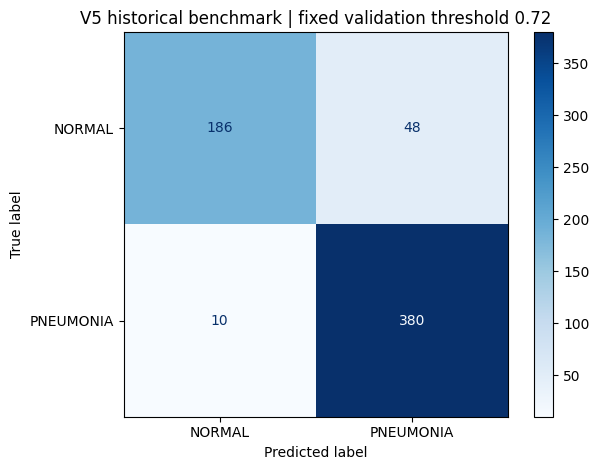

V5 historical pass complete. No threshold or model adjustment follows this score.


In [15]:
# One frozen historical-benchmark comparison. No further choice is made from these results.
assert hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest() == json.loads((V3_DIR / 'locked_policy.json').read_text())['model_sha256']
if (V3_DIR / 'historical_test_predictions.csv').exists():
    v3_test_frame = pd.read_csv(V3_DIR / 'historical_test_predictions.csv')
    print('Reusing the stored historical-test predictions; no second inference pass.')
else:
    v3_historical_ds = v3_ordered_dataset(test_file_paths).prefetch(tf.data.AUTOTUNE)
    v3_historical_prob = v3_predict(v3_restored_model, v3_historical_ds)
    v3_test_frame = pd.DataFrame({'file': v3_manifest['files']['historical_test'],
        'y_true': [class_names.index(Path(p).parent.name) for p in test_file_paths],
        'p_pneumonia': v3_historical_prob})
    v3_test_frame['y_pred'] = (v3_test_frame['p_pneumonia'] >= V3_THRESHOLD).astype(int)
    v3_test_frame.to_csv(V3_DIR / 'historical_test_predictions.csv', index=False)
v3_test_y = v3_test_frame['y_true'].to_numpy()
v3_test_prob = v3_test_frame['p_pneumonia'].to_numpy()
v3_test_pred = (v3_test_prob >= V3_THRESHOLD).astype(int)
v3_test_result = v3_metrics(v3_test_y, v3_test_prob, V3_THRESHOLD)
v3_test_result.update(roc_auc=float(roc_auc_score(v3_test_y, v3_test_prob)), n=len(v3_test_y),
    name='V5_EfficientNetV2B0_320', members=V3_MEMBERS, selected_candidate=v3_selected['name'],
    independent_unseen_test=False, benchmark='previously_inspected_official_test')
(V3_DIR / 'historical_test_metrics.json').write_text(json.dumps(v3_test_result, indent=2))

# These baseline counts are the verified saved notebook results, not re-tuned models.
v1_counts = {'name': 'Original_test_selected_0.85', 'threshold': 0.85, 'tn': 201, 'fp': 33, 'fn': 18, 'tp': 372}
v2_counts = {'name': 'Corrected_MobileNetV2_validation_0.30', 'threshold': 0.30, 'tn': 156, 'fp': 78, 'fn': 4, 'tp': 386}
def metrics_from_counts(row):
    tn, fp, fn, tp = [row[k] for k in ('tn', 'fp', 'fn', 'tp')]
    return dict(row, accuracy=(tn + tp)/(tn+fp+fn+tp), precision=tp/(tp+fp), recall=tp/(tp+fn),
        specificity=tn/(tn+fp), f1=2*tp/(2*tp+fp+fn))
v3_reference = dict(V3_COMPLETED_RESULT) if V3_COMPLETED_RESULT else metrics_from_counts(
    {'name': 'V3_Grouped_DenseNet121', 'threshold': 0.65, 'tn': 177, 'fp': 57, 'fn': 7, 'tp': 383})
v3_reference['name'] = 'V3_Grouped_DenseNet121'
v4_reference = dict(V4_COMPLETED_RESULT) if V4_COMPLETED_RESULT else metrics_from_counts(
    {'name':'V4_Normalized_DenseNet121','threshold':0.64,'tn':177,'fp':57,'fn':10,'tp':380})
v4_reference['name']='V4_Normalized_DenseNet121'
v3_benchmarks = [metrics_from_counts(v1_counts), metrics_from_counts(v2_counts), v3_reference, v4_reference, v3_test_result]
v3_benchmark_frame = pd.DataFrame(v3_benchmarks)
v3_benchmark_frame.to_csv(V3_DIR / 'historical_benchmark_comparison.csv', index=False)
v3_original = v3_benchmarks[0]
v3_vs_original = {k: {'original': v3_original[k], 'v5': v3_test_result[k],
    'v5_strictly_higher': bool(v3_test_result[k] > v3_original[k])} for k in ['accuracy', 'precision', 'recall', 'f1', 'specificity']}
(V3_DIR / 'comparison_to_original.json').write_text(json.dumps(v3_vs_original, indent=2))
print('HISTORICAL BENCHMARK COMPARISON')
print(v3_benchmark_frame[['name', 'threshold', 'accuracy', 'precision', 'recall', 'specificity', 'f1', 'tn', 'fp', 'fn', 'tp']].to_string(index=False))
print('Selected candidate:', v3_selected['name'])
print('Historical test ROC-AUC:', v3_test_result['roc_auc'])
print('All four classification metrics strictly exceed original:', all(v3_vs_original[k]['v5_strictly_higher'] for k in ['accuracy', 'precision', 'recall', 'f1']))
print('This is a descriptive historical comparison; model development was motivated by earlier benchmark results.')
v3_report = classification_report(v3_test_y, v3_test_pred, labels=[0, 1], target_names=class_names, digits=4, zero_division=0)
(V3_DIR / 'classification_report.txt').write_text(v3_report)
print(v3_report)
v3_cm = confusion_matrix(v3_test_y, v3_test_pred, labels=[0, 1])
ConfusionMatrixDisplay(v3_cm, display_labels=class_names).plot(cmap='Blues')
plt.title(f'V5 historical benchmark | fixed validation threshold {V3_THRESHOLD:.2f}')
plt.tight_layout()
plt.savefig(V3_DIR / 'historical_test_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()
print("V5 historical pass complete. No threshold or model adjustment follows this score.")


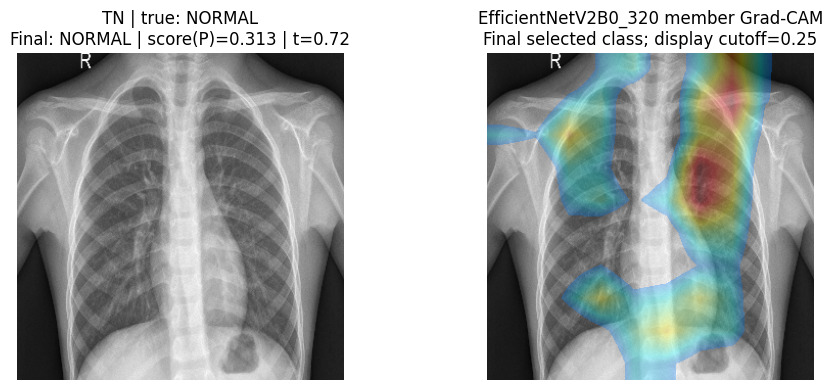

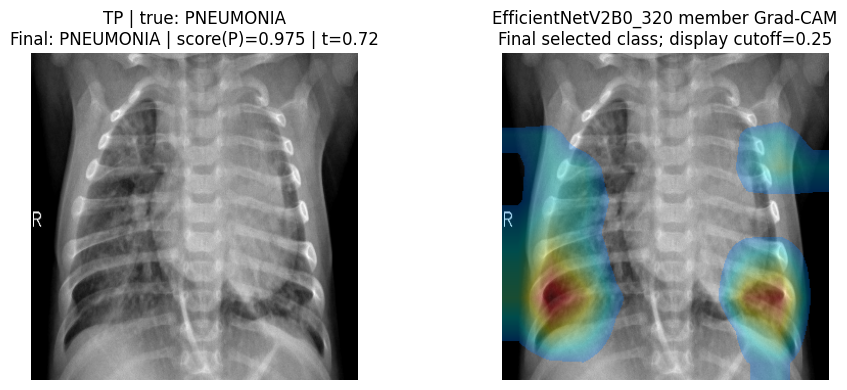

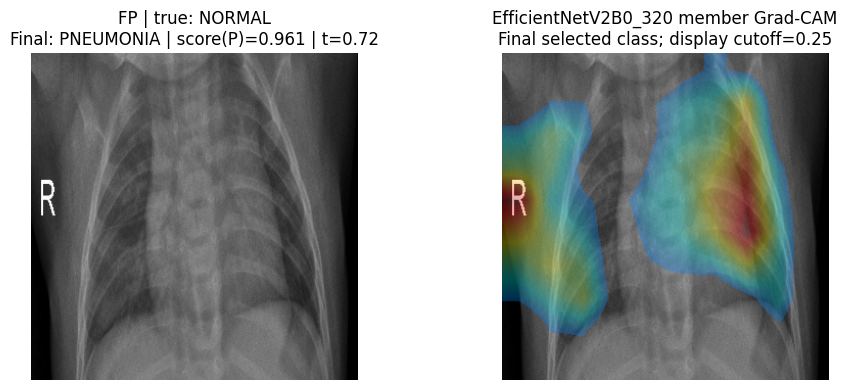

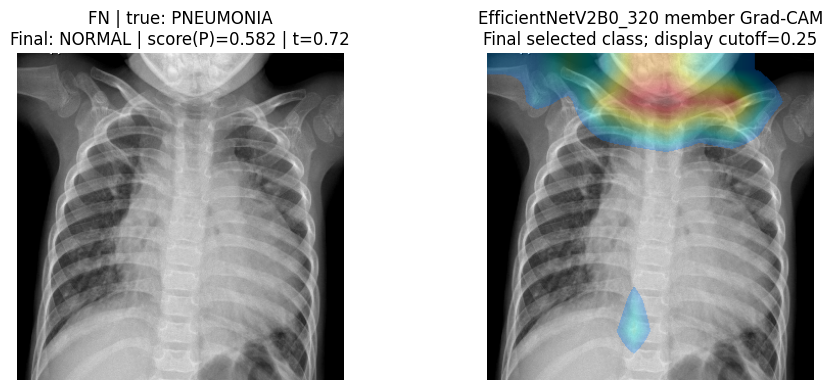

First-in-file-order examples were used; no selection for attractive heatmaps.


In [16]:
# Member Grad-CAM for the class selected by the final model/ensemble.
# For an ensemble, this displays each member separately and is not a full explanation of the mean model.
def v3_image(path):
    image = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
    return tf.image.resize(image, (320, 320), method='bilinear')[None, ...]

def v3_member_gradcam(member, image, explain_pneumonia):
    grad_model = tf.keras.Model(member.inputs, [member.get_layer('last_conv_features').output, member.outputs[0]])
    with tf.GradientTape() as tape:
        features, score = grad_model(image, training=False)
        target = score[:, 0] if explain_pneumonia else 1.0 - score[:, 0]
    gradient = tape.gradient(target, features)
    if gradient is None:
        raise RuntimeError('Member Grad-CAM graph is disconnected.')
    weights = tf.reduce_mean(tf.cast(gradient, tf.float32), axis=(0, 1, 2))
    heatmap = tf.reduce_sum(tf.cast(features[0], tf.float32) * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    return (heatmap / (tf.reduce_max(heatmap) + 1e-8)).numpy()

def v3_show_case(path, category, heatmap_cutoff=0.25, alpha=0.30):
    image = v3_image(path)
    score = float(np.asarray(v3_restored_model(image, training=False)).ravel()[0])
    decision = int(score >= V3_THRESHOLD)
    original = np.clip(image.numpy()[0], 0, 255).astype(np.uint8)
    fig, axes = plt.subplots(1, len(V3_MEMBERS) + 1, figsize=(5*(len(V3_MEMBERS)+1), 4))
    axes = np.atleast_1d(axes)
    axes[0].imshow(original)
    axes[0].set_title(f'{category} | true: {Path(path).parent.name}\nFinal: {class_names[decision]} | score(P)={score:.3f} | t={V3_THRESHOLD:.2f}')
    for ax, name in zip(axes[1:], V3_MEMBERS):
        heatmap = cv2.resize(v3_member_gradcam(v3_member_models[name], image, bool(decision)), (320, 320))
        mask = heatmap >= heatmap_cutoff
        colors = cv2.cvtColor(cv2.applyColorMap(np.uint8(255*heatmap), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
        blended = np.clip((1-alpha)*original.astype(float) + alpha*colors.astype(float), 0, 255)
        ax.imshow(np.where(mask[..., None], blended, original).astype(np.uint8))
        ax.set_title(f'{name} member Grad-CAM\nFinal selected class; display cutoff={heatmap_cutoff:.2f}')
    for ax in axes:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(V3_DIR / f'{category}_{Path(path).stem}_member_gradcam.png', dpi=140, bbox_inches='tight')
    plt.show()

v3_case_groups = {
    'TN': np.flatnonzero((v3_test_y == 0) & (v3_test_pred == 0)),
    'TP': np.flatnonzero((v3_test_y == 1) & (v3_test_pred == 1)),
    'FP': np.flatnonzero((v3_test_y == 0) & (v3_test_pred == 1)),
    'FN': np.flatnonzero((v3_test_y == 1) & (v3_test_pred == 0))}
v3_examples = []
for category, indices in v3_case_groups.items():
    if not len(indices):
        print(category, 'has no example at the locked threshold.')
        continue
    index = int(indices[0])
    path = test_file_paths[index]
    v3_examples.append({'category': category, 'file': str(Path(path).relative_to(base_dir))})
    v3_show_case(path, category)
(V3_DIR / 'gradcam_examples.json').write_text(json.dumps(v3_examples, indent=2))
print('First-in-file-order examples were used; no selection for attractive heatmaps.')


In [17]:
# Integrity checks, reproducible export and a precise result summary.
import zipfile
import platform
import sklearn

def normal_filename_source(path):
    return "NORMAL2" if Path(path).name.startswith("NORMAL2-") else "IM"

v3_manifest['historical_test_hashes'] = {str(Path(p).relative_to(base_dir)): v3_test_digests[str(p)] for p in test_file_paths}
v3_manifest['filename_proxy_keys'] = {s: [filename_group(p) for p in paths] for s, paths in
    [('train', v3_fit_paths), ('validation', v3_dev_paths), ('historical_test', test_file_paths)]}
v3_manifest['identity_audit'] = {
    'source_train_test_shared_proxy_keys_before_exclusion': len({filename_group(p) for p in all_source_train} & v3_test_groups),
    'source_train_test_shared_byte_hashes_before_exclusion': len(set(train_digest_map.values()) & v3_test_hashes),
    'final_train_validation_shared_proxy_keys': len(set(v3_manifest['filename_proxy_keys']['train']) & set(v3_manifest['filename_proxy_keys']['validation'])),
    'final_pool_test_shared_proxy_keys': len((set(v3_manifest['filename_proxy_keys']['train']) | set(v3_manifest['filename_proxy_keys']['validation'])) & v3_test_groups),
    'final_pool_test_shared_byte_hashes': len(set(v3_manifest['hashes'].values()) & v3_test_hashes)
}
assert v3_manifest['identity_audit']['final_train_validation_shared_proxy_keys'] == 0
assert v3_manifest['identity_audit']['final_pool_test_shared_proxy_keys'] == 0
assert v3_manifest['identity_audit']['final_pool_test_shared_byte_hashes'] == 0
(V3_DIR / 'split_manifest.json').write_text(json.dumps(v3_manifest, indent=2))
assert np.array_equal(v3_test_pred, (v3_test_prob >= V3_THRESHOLD).astype(int))
assert v3_cm.tolist() == [[v3_test_result['tn'], v3_test_result['fp']], [v3_test_result['fn'], v3_test_result['tp']]]
assert hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest() == v3_locked_policy['model_sha256']
v3_environment = {'python': platform.python_version(), 'tensorflow': tf.__version__,
    'keras': tf.keras.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
    'sklearn': sklearn.__version__, 'mixed_precision': tf.keras.mixed_precision.global_policy().name,
    'selected_model_sha256': v3_locked_policy['model_sha256'],
    'members': V3_MEMBERS, 'decision_threshold': V3_THRESHOLD, 'dataset_root': str(base_dir)}
(V3_DIR / 'environment.json').write_text(json.dumps(v3_environment, indent=2))
v3_all_better = all(v3_vs_original[k]['v5_strictly_higher'] for k in ['accuracy', 'precision', 'recall', 'f1'])
v3_summary = f'''# Pneumonia V5 - EfficientNetV2B0 320px and Source-Stratified Validation

Selected model: {v3_selected['name']}
Decision threshold: {V3_THRESHOLD:.2f}, locked on grouped internal validation.
Training/validation/historical-test sizes: {len(v3_fit_paths)} / {len(v3_dev_paths)} / {len(test_file_paths)}.
Validation precision: {v3_selected['precision']:.6f}
Validation recall: {v3_selected['recall']:.6f}
Validation specificity: {v3_selected['specificity']:.6f}

Historical-test accuracy: {v3_test_result['accuracy']:.6f}
Historical-test precision: {v3_test_result['precision']:.6f}
Historical-test recall: {v3_test_result['recall']:.6f}
Historical-test F1: {v3_test_result['f1']:.6f}
Historical-test ROC-AUC: {v3_test_result['roc_auc']:.6f}
Confusion matrix [[TN, FP], [FN, TP]]: {v3_cm.tolist()}
All four metrics strictly exceed saved original: {v3_all_better}

V3 and V4 results are preserved as earlier adaptive development stages.
V5 was designed after those historical scores. It trains one fresh EfficientNetV2B0 at 320px,
with built-in preprocessing, geometric and photometric augmentation, balanced class weights,
and source-stratified grouped validation covering both NORMAL filename prefixes.
Checkpoint and deployment threshold selection retain validation precision/recall >=0.95.
No model or threshold adjustment follows the V5 historical score.
Filename prefixes are domain proxies, not verified scanner/site labels.
The earlier image-level split had {v3_audit['byte_identical_hashes_shared_train_validation']} exact-byte hashes and {v3_audit['filename_proxy_groups_shared_train_validation']} filename-proxy groups shared across training and validation.
V3 separates proxy groups and exact bytes; clinical patient identity and near-duplicates remain unverified.
The official test has already been inspected and informed the improvement request. These are descriptive historical-benchmark results, not independent unseen-test evidence or a clinical-performance claim.
Grad-CAM examples explain individual members for the final selected class. Ensemble member maps do not constitute a full explanation of the mean model.

Load selected_model.keras with tf.keras.models.load_model(path, compile=False).
Input: RGB float32 image resized bilinearly to 320 x 320, pixels 0..255. Model-specific normalization is embedded.
Output: uncalibrated PNEUMONIA score; classify as PNEUMONIA when score >= locked_policy.json decision_threshold.
'''
(V3_DIR / 'RUN_SUMMARY.md').write_text(v3_summary)

chart_metrics = ['accuracy', 'precision', 'recall', 'f1']
chart_labels = ['Accuracy', 'Pneumonia precision', 'Pneumonia recall', 'Pneumonia F1']
positions = np.arange(len(chart_metrics))
fig, ax = plt.subplots(figsize=(12, 5.5))
for offset, (row, label, color) in enumerate(zip(v3_benchmarks,
        ['Original (test-selected threshold)', 'Corrected MobileNetV2', 'V3 grouped DenseNet121', 'V4 normalized DenseNet121', 'V5 EfficientNetV2B0 320px'],
        ['#8c98a7', '#e7a654', '#6a7faa', '#b182ad', '#167d8d'])):
    values = [100 * row[key] for key in chart_metrics]
    bars = ax.bar(positions + (offset-2)*0.16, values, width=0.16, label=label, color=color)
    ax.bar_label(bars, labels=[f'{v:.2f}' for v in values], padding=3, fontsize=8)
ax.set_xticks(positions, chart_labels)
ax.set_ylim(0, 110)
ax.set_ylabel('Percent')
ax.set_title('Same historical benchmark: five saved project versions\nDifferent training and selection protocols; descriptive comparison')
ax.legend(loc='lower left', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(V3_DIR / 'five_version_comparison.png', dpi=170, bbox_inches='tight')
plt.close(fig)

# Keep the self-contained selected inference model plus all development evidence.
# Training checkpoints and redundant individual candidate models remain in runtime, outside the deliverable archive.
(V3_DIR / 'historical_normal_source_error_counts.json').write_text(json.dumps({source: {
    'normal_images': len(frame), 'false_positive': int(frame['y_pred'].sum())}
    for source, frame in v3_test_frame.loc[v3_test_frame.y_true == 0].assign(
        source=lambda d: d['file'].map(normal_filename_source)).groupby('source')}, indent=2))

v3_archive_path = Path(str(V3_DIR) + '_DELIVERY.zip')
with zipfile.ZipFile(v3_archive_path, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=6) as archive:
    for path in sorted(V3_DIR.iterdir()):
        if path.is_file() and not path.name.endswith('.weights.h5') and (path.suffix != '.keras' or path.name == 'selected_model.keras'):
            archive.write(path, path.name)
print(v3_summary)
print('V5 DELIVERY ARCHIVE:', v3_archive_path)
print('Saved selected model:', V3_MODEL_PATH)
print('Selected model hash:', v3_locked_policy['model_sha256'])
print('Validation-only selection, threshold/prediction consistency and export checks passed.')


# Pneumonia V5 - EfficientNetV2B0 320px and Source-Stratified Validation

Selected model: EfficientNetV2B0_320
Decision threshold: 0.72, locked on grouped internal validation.
Training/validation/historical-test sizes: 3781 / 956 / 624.
Validation precision: 0.996947
Validation recall: 0.950509
Validation specificity: 0.992565

Historical-test accuracy: 0.907051
Historical-test precision: 0.887850
Historical-test recall: 0.974359
Historical-test F1: 0.929095
Historical-test ROC-AUC: 0.974567
Confusion matrix [[TN, FP], [FN, TP]]: [[186, 48], [10, 380]]
All four metrics strictly exceed saved original: False

V3 and V4 results are preserved as earlier adaptive development stages.
V5 was designed after those historical scores. It trains one fresh EfficientNetV2B0 at 320px,
with built-in preprocessing, geometric and photometric augmentation, balanced class weights,
and source-stratified grouped validation covering both NORMAL filename prefixes.
Checkpoint and deployment threshold selection

In [18]:
# Plain-text final summary for review; this does not select or retune any model.
assert v3_selected['name']=='EfficientNetV2B0_320'
assert hashlib.sha256(V3_MODEL_PATH.read_bytes()).hexdigest()==v3_locked_policy['model_sha256']
summary_lines=['PNOMONI - V5 SONUC OZETI',
    f'Model: EfficientNetV2B0 | RGB 320x320 | validation esigi: {V3_THRESHOLD:.2f}',
    'Ayni tarihsel veri: 624 goruntu. Gelistirmede daha once incelendi.',
    '',f'{"Surum":<17} {"Accuracy":>9} {"Precision":>10} {"Recall":>9} {"F1":>9} {"FP":>5} {"FN":>5}']
for label,row in zip(['Eski V1','Duzeltilen V2','Gruplu V3','Normalize V4','EfficientNetV2 V5'],v3_benchmarks):
    summary_lines.append(f'{label:<17} {100*row["accuracy"]:>8.2f}% {100*row["precision"]:>9.2f}% {100*row["recall"]:>8.2f}% {100*row["f1"]:>8.2f}% {row["fp"]:>5} {row["fn"]:>5}')
summary_lines += ['',f'V5 ROC-AUC: {v3_test_result["roc_auc"]:.6f}',
    'V1 ile dort metrikte ustunluk: '+str(all(v3_vs_original[k]['v5_strictly_higher'] for k in ['accuracy','precision','recall','f1'])),
    'Validation ile esik secimi, kayit ve model yeniden acma kontrolleri gecti.',
    'Bagimsiz yeni test / klinik ustunluk iddiasi yoktur.',
    'Son model ve tum sonuclar teslim ZIP dosyasinda saklandi.']
summary_text='\n'.join(summary_lines)+'\n'
(V3_DIR/'FINAL_SUMMARY_TR.txt').write_text(summary_text,encoding='utf-8')
with zipfile.ZipFile(v3_archive_path,'a',compression=zipfile.ZIP_DEFLATED) as archive:
    if 'FINAL_SUMMARY_TR.txt' not in archive.namelist():
        archive.write(V3_DIR/'FINAL_SUMMARY_TR.txt','FINAL_SUMMARY_TR.txt')
print(summary_text)


PNOMONI - V5 SONUC OZETI
Model: EfficientNetV2B0 | RGB 320x320 | validation esigi: 0.72
Ayni tarihsel veri: 624 goruntu. Gelistirmede daha once incelendi.

Surum              Accuracy  Precision    Recall        F1    FP    FN
Eski V1              91.83%     91.85%    95.38%    93.58%    33    18
Duzeltilen V2        86.86%     83.19%    98.97%    90.40%    78     4
Gruplu V3            89.74%     87.05%    98.21%    92.29%    57     7
Normalize V4         89.26%     86.96%    97.44%    91.90%    57    10
EfficientNetV2 V5    90.71%     88.79%    97.44%    92.91%    48    10

V5 ROC-AUC: 0.974567
V1 ile dort metrikte ustunluk: False
Validation ile esik secimi, kayit ve model yeniden acma kontrolleri gecti.
Bagimsiz yeni test / klinik ustunluk iddiasi yoktur.
Son model ve tum sonuclar teslim ZIP dosyasinda saklandi.

